# Predicting motion during maintained contact

Can a distribution over a contact tangent plane improve response predictions or provide useful uncertainty beyond a tuned point estimator? This pilot generates force and velocity from a constrained mechanical model, then compares the existing Bayesian tracker with force-aware point and linear-map controls.

This is a separate candidate replacement for the field example. Existing experiments and manuscript files are preserved. A positive result is not required. The model is an idealized **bilateral guide with known viscous resistance**, rather than general unilateral or frictional contact.

## From force balance to the observation model

For a surface with unit normal $n(p)$, negligible inertia and isotropic resistance $dI$, the plant solves

$$\begin{bmatrix}dI_3&-n(p)\\n(p)^\top&0\end{bmatrix}
\begin{bmatrix}\dot p\\\lambda\end{bmatrix}
=\begin{bmatrix}F\\0\end{bmatrix}.$$

Thus $\dot p=P F/d$, where $P=I-nn^\top$ projects onto the two-dimensional tangent plane. The filter receives $v=F/d$ and $u=\dot p+e$, with $e\sim N(0,sI_3)$. This is the draft's **conditional known-input model** on $\mathrm{Gr}(2,3)$.

The plant uses geometric normals and an independent force-balance solve. Sphere motion is integrated with surface-drift control. Observations are instantaneous solver velocities, not finite differences of positions. The simulated positions shown below are **plant/scoring records only**; estimators receive the same force and noisy velocity streams. Consequently this pilot makes no claim of practical superiority over methods using position encoders.

In [1]:
from pathlib import Path
import sys,json,hashlib,subprocess
ROOT=Path.cwd() if (Path.cwd()/'lib').exists() else Path.cwd().parent
sys.path.insert(0,str(ROOT))
from lib.contact_validation import require_contact_gate
from lib.contact_reporting import load_contact
from lib.contact_visuals import (physical_setup,paired_losses,coverage_width,
    response_intervals,risk_calibration,benchmark_losses,runtime,mechanical_diagnostics,
    validation_curves)
from lib.plotting import plt
from IPython.display import display,Markdown
import pandas as pd
OUT=ROOT/'results/contact_pilot'
gate=require_contact_gate(ROOT)
assert plt.rcParams['text.usetex'] is True
assert plt.rcParams['figure.dpi']==200 and plt.rcParams['savefig.dpi']==200
subprocess.run([sys.executable,str(ROOT/'scripts/run_contact_pilot.py'),'--workers','2'],cwd=ROOT,check=True)
frames=load_contact(ROOT)
print('Validation:',gate['status'],'checks:',gate['tests'])
display(pd.Series(frames['config'])[['T','dt','d','v0','sigma','validation_trials','test_trials','primary_condition']])
def show(fig):
    display(fig)
    plt.close(fig)


Contact pilot: verified cached tables


Validation: passed checks: 88


T                             600
dt                           0.05
d                            10.0
v0                           0.02
sigma                       0.001
validation_trials              16
test_trials                    64
primary_condition    sphere_small
dtype: object

## Physical trajectories and tangent planes

The plane has a fixed non-axis-aligned normal. Spheres have radii 0.20 m and 0.05 m, with independently randomized initial orientations. The curved guides use a bounded world-frame force program. The weak-input condition reduces two force components by five; its uncertainty is measured, not assumed. The applied force does not depend on a hidden subspace rotation.

Geometry and true normals enter only the plant and scoring. Arrows compare the free velocity $F/d$ with the constrained velocity. A maintained guide permits signed reaction forces: separation, impacts, friction cones and changing contact modes are outside this experiment.

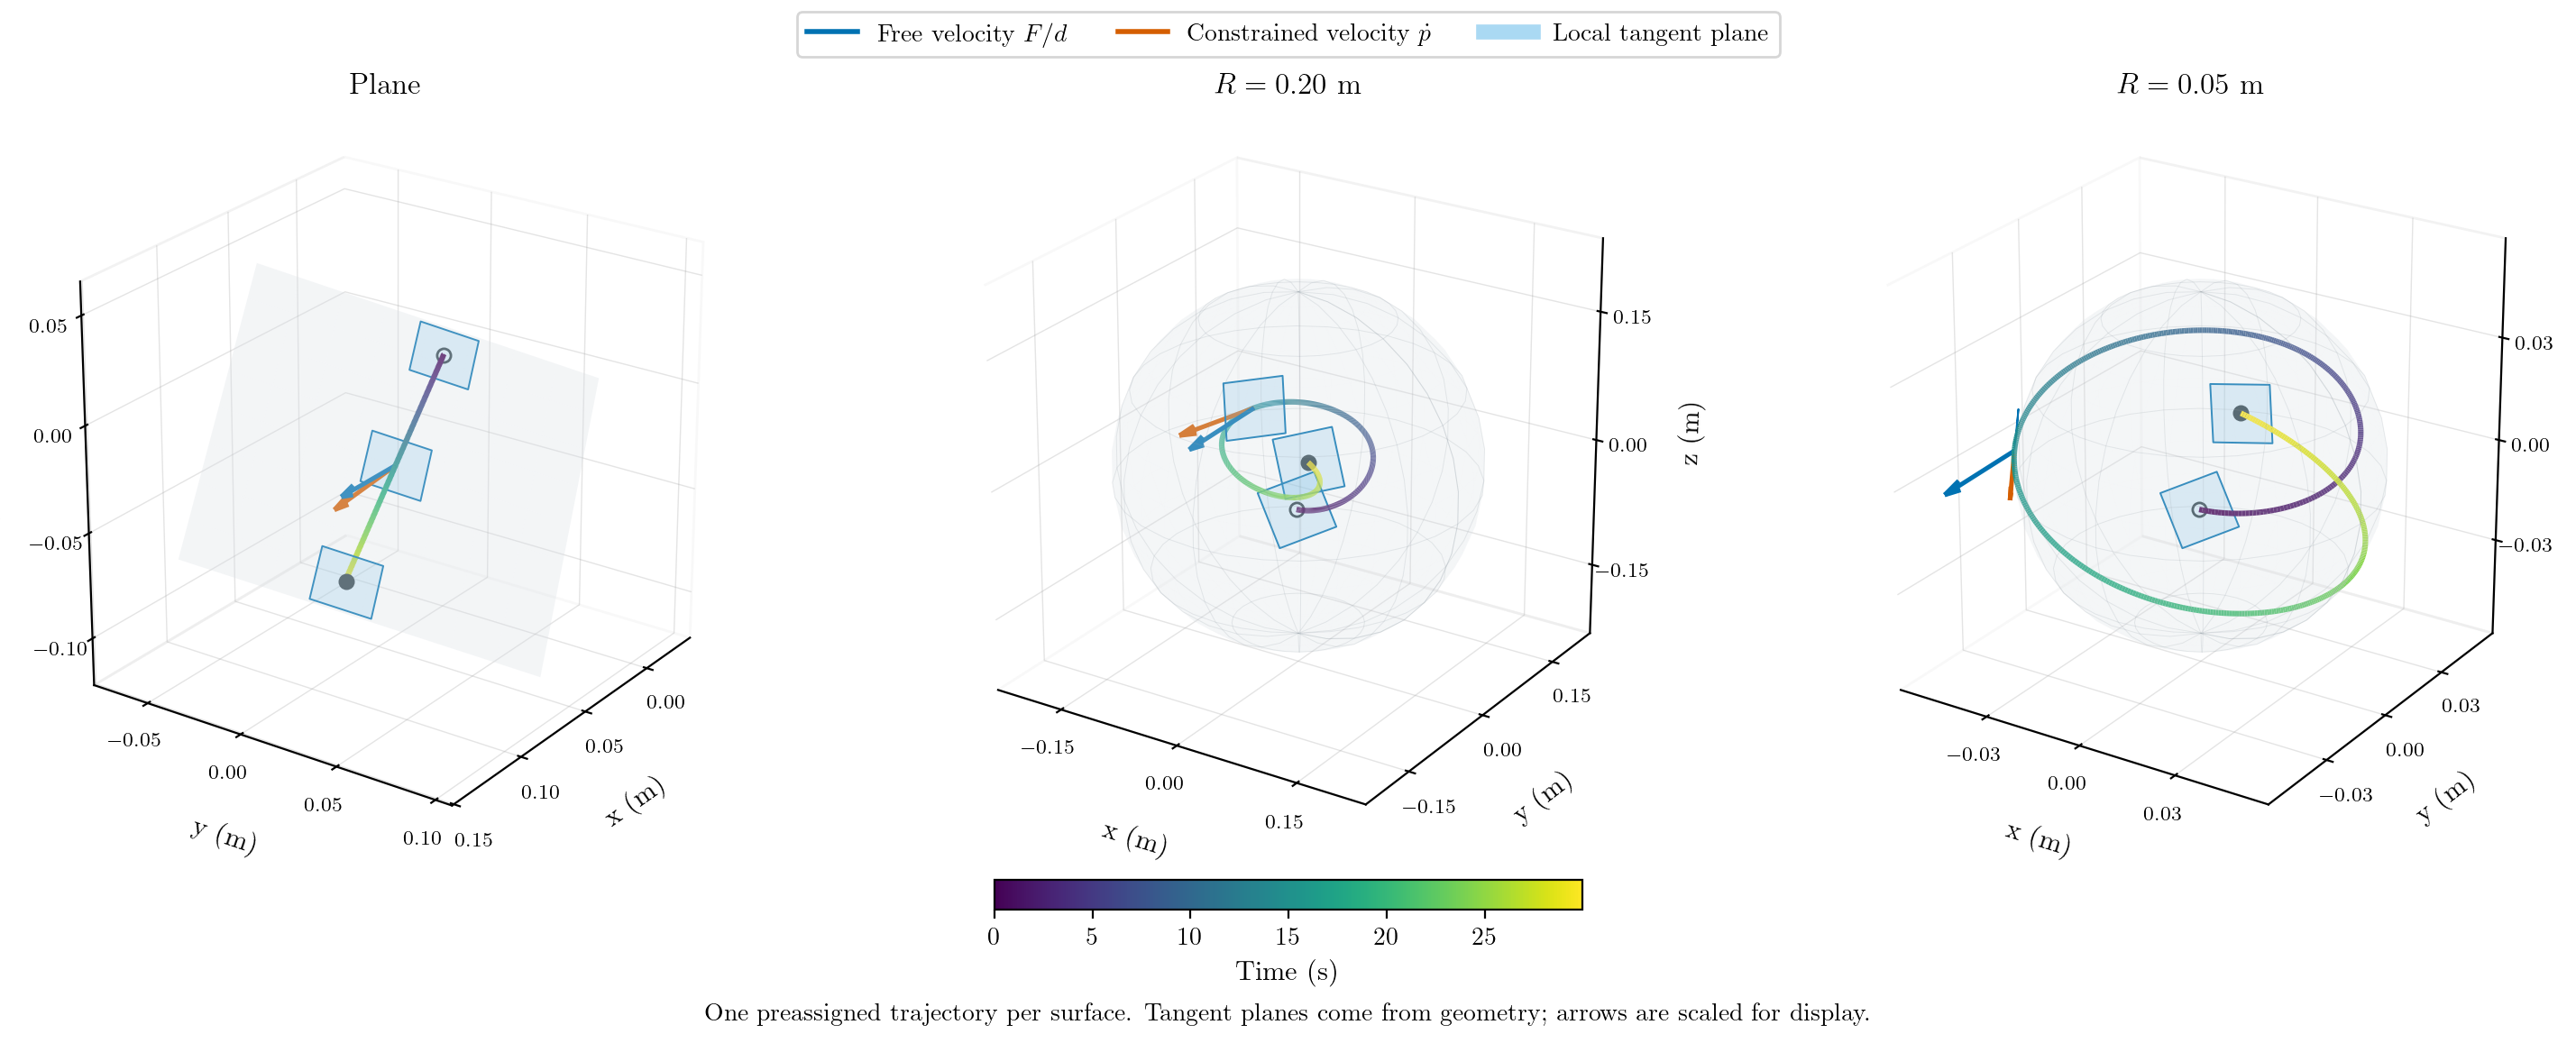

In [2]:
show(physical_setup(frames,path=OUT/'figures/physical_setup'))

## Numerical and model checks

The tangent-plane posterior has the normal-line complement
$$\bar P(A)=I_3-E_{q_{-A},k=1}[nn^\top].$$
The existing spectral backend is used where its truncation budget resolves. The static plane reaches concentration spans of order $8\times10^4$, beyond that backend's default finite-order budget. A separate concentration-adapted sphere integration handles this regime without changing the existing numerical core. Continuous radial CDFs determine response quantiles; weighted node quantiles are avoided.

Moments, state thresholds and scalar response endpoints each receive resolution checks. Independent pole/ridge integrals test concentrations through $10^6$. Resolution agreement and quadrature error estimates are numerical evidence, not rigorous roundoff enclosures. Unresolved flags remain visible.

The mode is also compared with an independently calculated weighted projector least-squares solution. Their equality checks the implementation; it does not establish an accuracy gain.

In [3]:
numeric=json.loads((OUT/'numerics/checks.json').read_text())
for name,digest in numeric['sources'].items():
    assert hashlib.sha256((ROOT/name).read_bytes()).hexdigest()==digest,name
display(pd.Series(numeric)[['status','physical_targets','maximum_span',
    'maximum_mean_resolution_error','maximum_quantile_relative_error',
    'maximum_region_radius_scaled_error','maximum_region_hpd_scaled_error']])
display(pd.Series(frames['metadata']['checks']))
mechanics=json.loads((OUT/'numerics/mechanics_checks.json').read_text())
display(pd.Series(mechanics)[['status','maximum_position_difference',
    'maximum_velocity_difference','maximum_velocity_difference_over_sigma']])


status                                    passed
physical_targets                              63
maximum_span                          79691.0884
maximum_mean_resolution_error                0.0
maximum_quantile_relative_error         0.002066
maximum_region_radius_scaled_error           0.0
maximum_region_hpd_scaled_error              0.0
dtype: object

posterior_evaluations                          960
numerical_failures                               0
mean_numerical_failures                          0
state_region_numerical_failures                  0
response_interval_numerical_failures             0
selected_validation_numerical_failures           0
maximum_ls_parameter_error                     0.0
maximum_ls_projector_error                     0.0
maximum_ls_objective_error                     0.0
theorem_applicable                             768
theorem_valid                                  389
valid_certificate_violations                     0
maximum_matched_projection_identity_error      0.0
maximum_surface_error                          0.0
no_mcmc                                       True
no_noise_learning                             True
positions_available_to_estimators            False
dtype: object

status                                    passed
maximum_position_difference                  0.0
maximum_velocity_difference                  0.0
maximum_velocity_difference_over_sigma       0.0
dtype: object

## Response predictions against tuned controls

Nine fixed queries have norm $v_0$: coordinate directions and normalized pairwise sums/differences. They represent hypothetical forces applied at the **current** contact position; they do not advance the tool or predict a future trajectory. The primary endpoint averages the squared three-component response error over these queries within each trajectory, at observation 600.

Each method's memory is selected using independent validation task loss and frozen across the curved test conditions. The stationary plane is a separate $\beta=1$ control. Comparisons include the same-posterior mode, independently tuned mode, scalar shrinkage, ridge force-to-velocity regression, and a cheap velocity-only PCA control. For each memory, scalar shrinkage is optimized continuously on pooled validation loss; a coarse endpoint grid cannot create an artificial posterior advantage.

The primary condition is the smaller-radius balanced guide, with two preselected references: shrinkage and ridge. Other pointwise intervals are exploratory. The 64 independent trajectories are the statistical replicates; query coordinates and report times do not increase that count. A gain over velocity-only PCA primarily demonstrates the value of knowing applied force. A gain over ridge can reflect the projector constraint; the mode/shrinkage comparisons isolate what the full distribution adds.

,scope,method,beta,rho,regularization
0,plane,Posterior mean,1.0,NaN,NaN
1,plane,Tuned mode,1.0,NaN,NaN
2,plane,Velocity PCA,1.0,NaN,NaN
3,plane,Scalar shrinkage,1.0,0.999976,NaN
4,plane,Ridge map,1.0,NaN,0.0
5,curved,Posterior mean,0.8,NaN,NaN
6,curved,Tuned mode,0.8,NaN,NaN
7,curved,Velocity PCA,1.0,NaN,NaN
8,curved,Scalar shrinkage,0.8,0.971516,NaN
9,curved,Ridge map,1.0,NaN,0.1


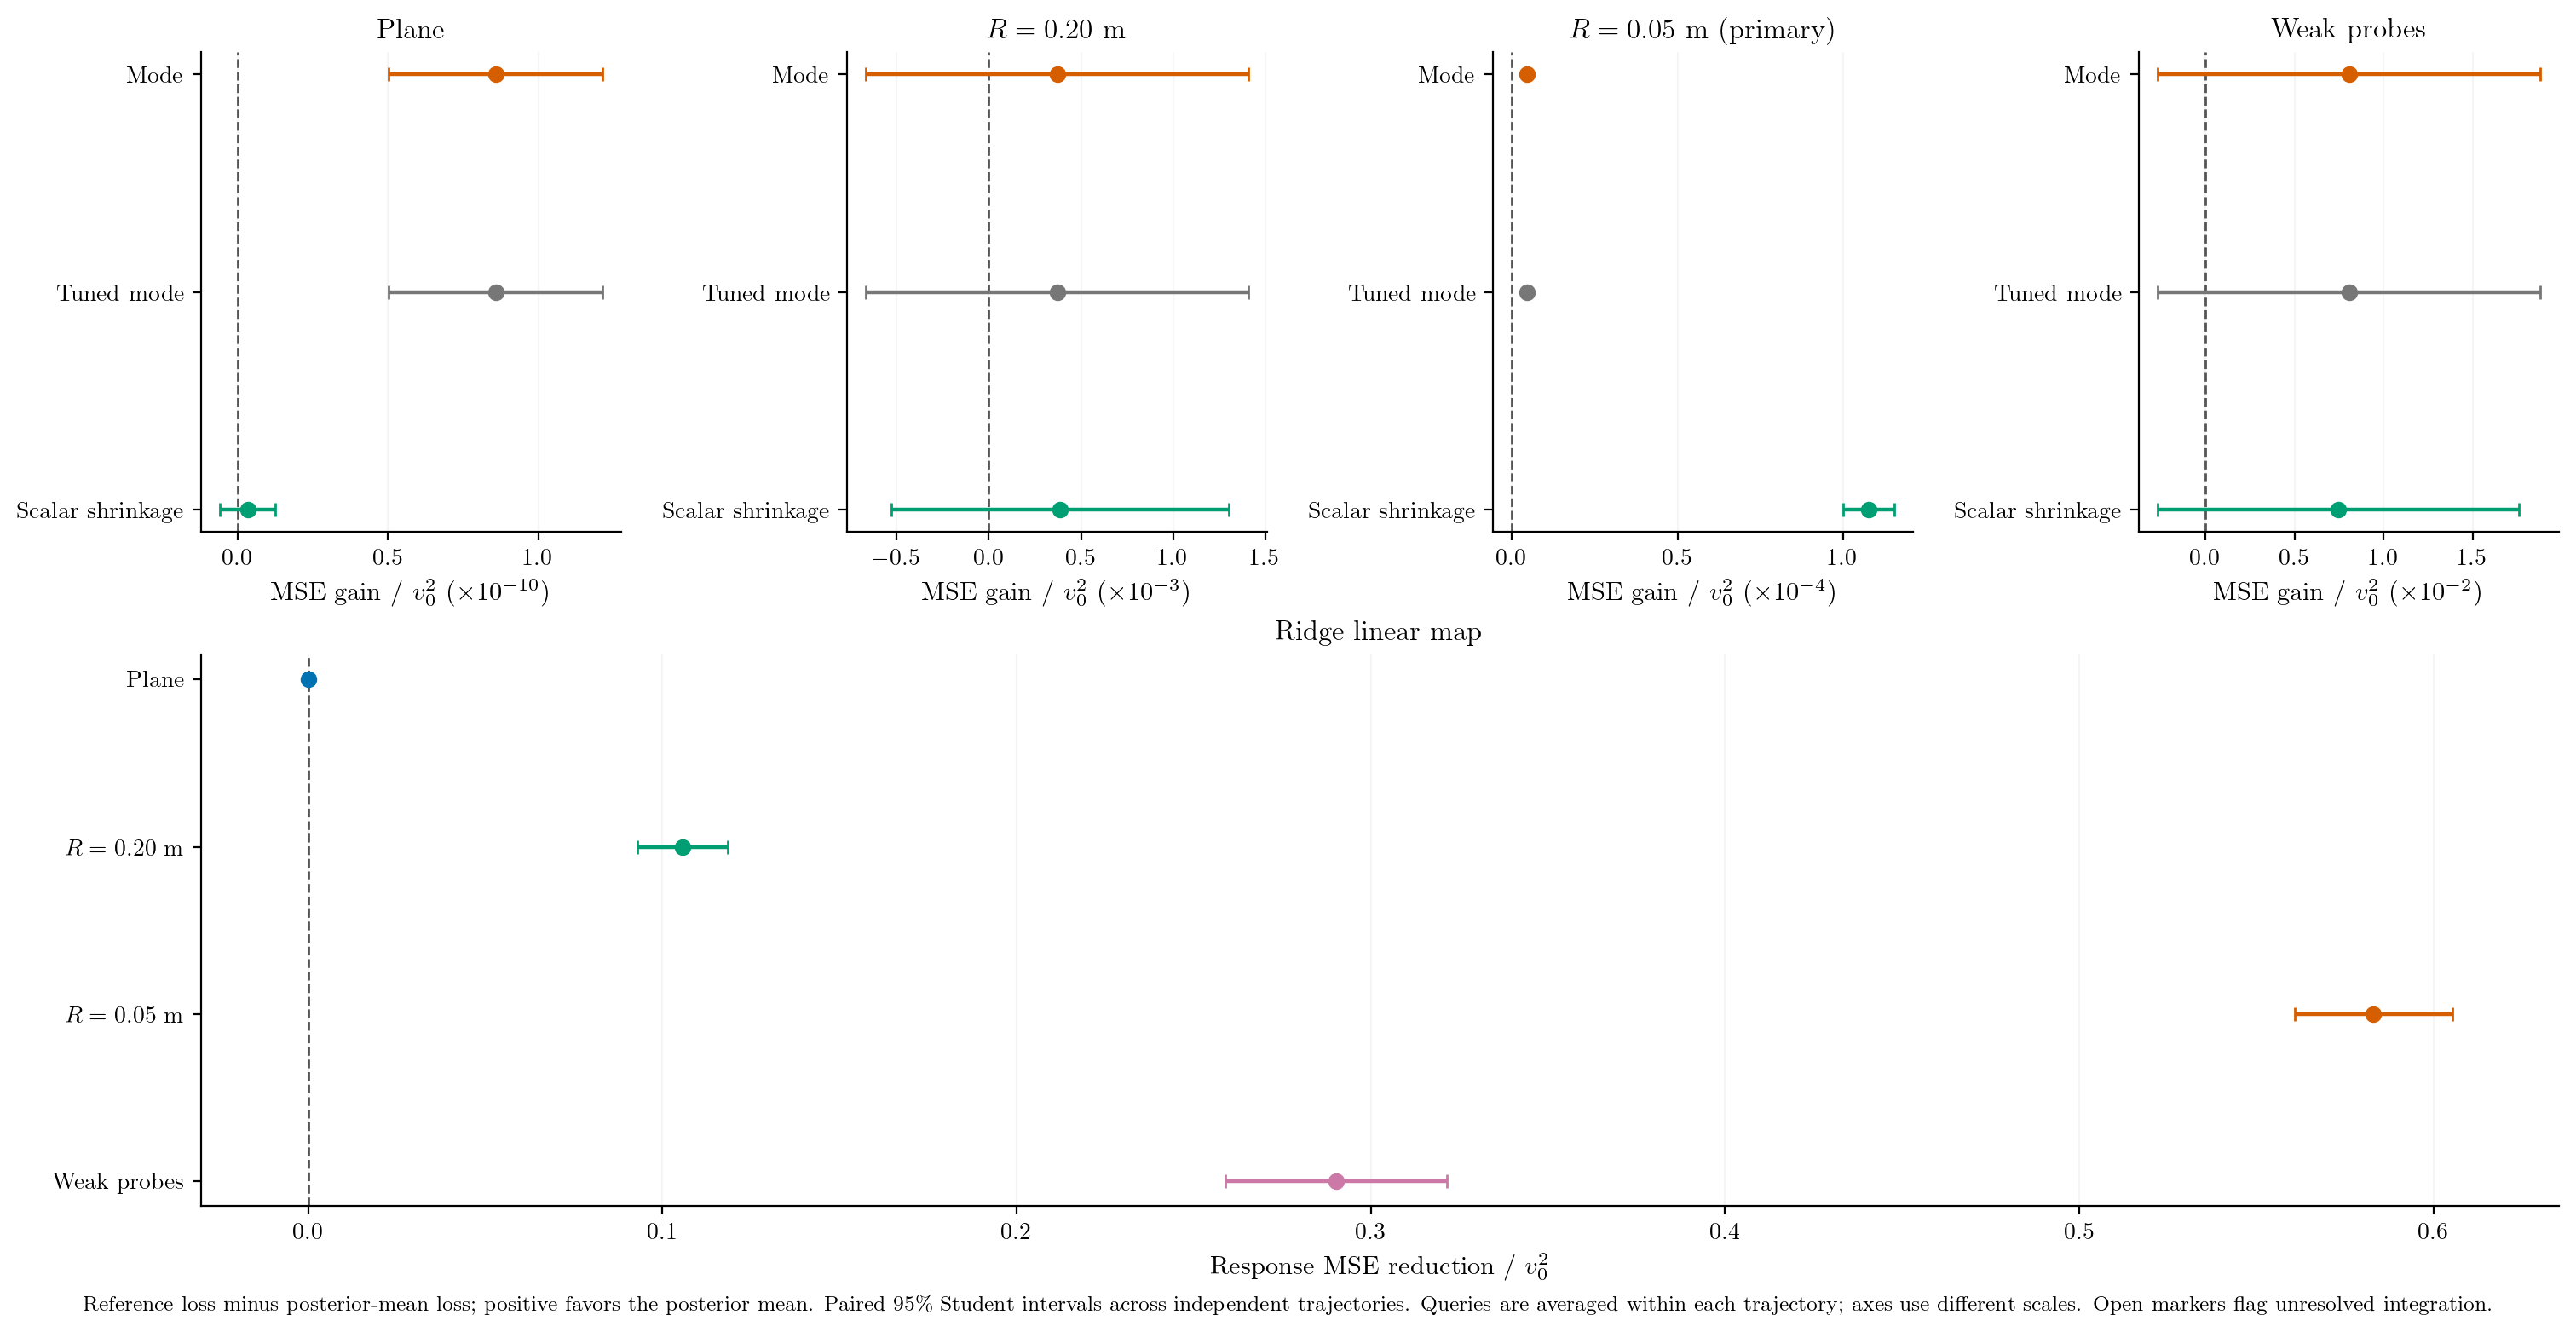

,condition,reference,trials,gain,low,high,mean_loss,reference_loss,normalized_gain,normalized_low,normalized_high,primary,numerical_failures,interval,selected_validation_numerical_failures,numerically_resolved
12,sphere_small,Scalar shrinkage,64,4.303875e-08,3.993423e-08,4.614328e-08,0.000001,0.000001,0.000108,0.000100,0.000115,True,0,Two preselected references at primary conditio...,0,True
13,sphere_small,Ridge map,64,2.332002e-04,2.243231e-04,2.420772e-04,0.000001,0.000234,0.583000,0.560808,0.605193,True,0,Two preselected references at primary conditio...,0,True


In [4]:
display(pd.DataFrame(frames['metadata']['selected']))
show(paired_losses(frames,path=OUT/'figures/paired_losses'))
display(frames['paired'][frames['paired'].primary.astype(bool)])

## Coverage and interval width

State balls, state HPD regions, and componentwise clean-response intervals answer different questions. Their sizes have different units. State coverage uses Wilson intervals across trajectories; average component coverage first averages the 27 query/component indicators within a trajectory. These are pointwise summaries, not simultaneous coverage of all responses or a motion path.

The balanced stationary control matches the observation and state model. At complete input cycles, its isotropic input Gram and rotation symmetry make state-region coverage a clean check. Fixed-world functional central intervals need not inherit that state-coverage property, particularly near extremal responses.

On curved guides, identity prediction and discounting are approximations. Nominal posterior mass does not guarantee physical-state coverage. Widths normalized by $v_0$ reveal whether an apparently reliable interval is nearly uninformative. No noisy-observation intervals are computed in this pilot; every response band below concerns the clean mechanical response.

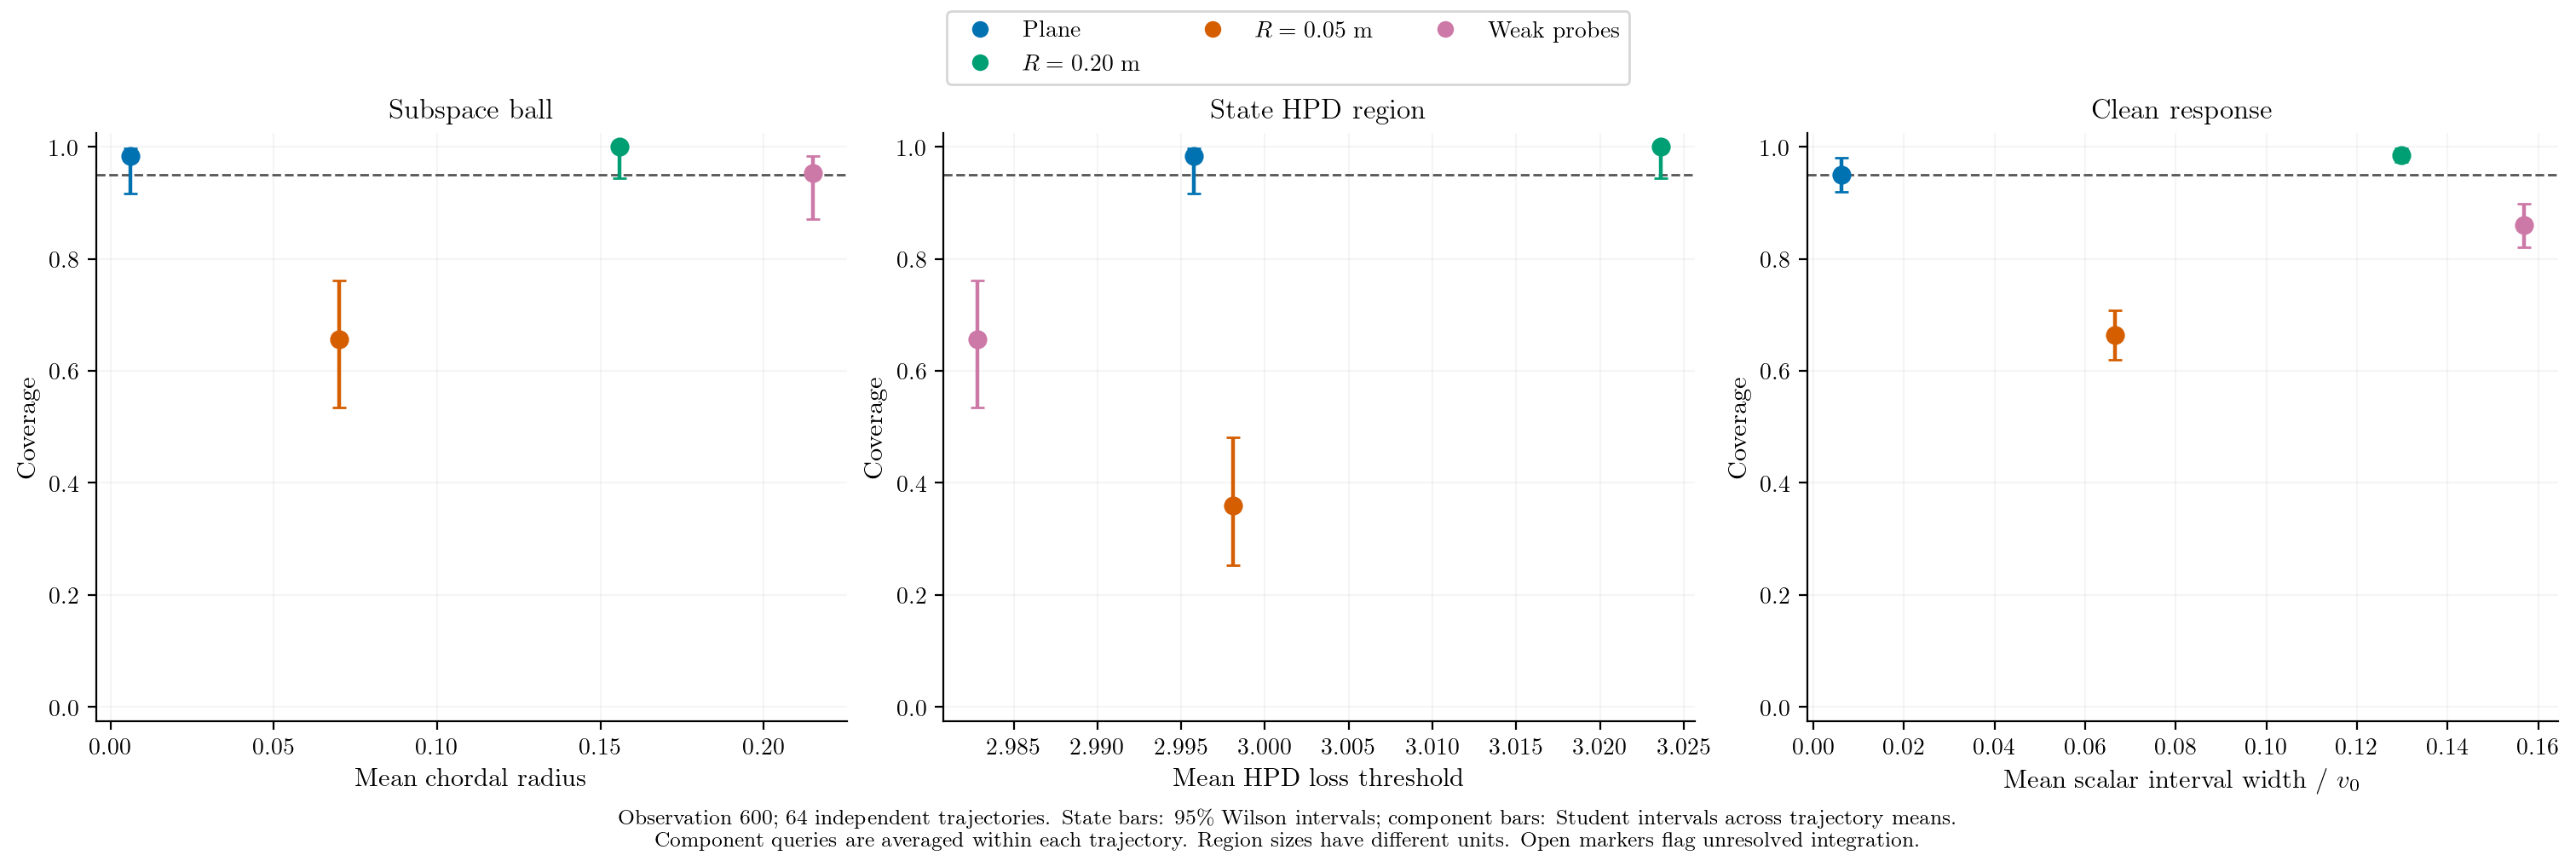

,condition,t,region,successes,trials,coverage,low,high,mean_width,width_quantity,numerical_failures,interval
6,plane,600,State ball,63.0,64,0.984375,0.916657,0.997237,0.006117,ball_radius,0,Wilson across independent trajectories
7,plane,600,State HPD,63.0,64,0.984375,0.916657,0.997237,2.995751,hpd_threshold,0,Wilson across independent trajectories
8,plane,600,Clean response,NaN,64,0.950231,0.919208,0.981255,0.006121,mean component interval width / v0,0,Student across trajectory means of27 component...
15,sphere_large,600,State ball,64.0,64,1.000000,0.943374,1.000000,0.155754,ball_radius,0,Wilson across independent trajectories
16,sphere_large,600,State HPD,64.0,64,1.000000,0.943374,1.000000,3.023609,hpd_threshold,0,Wilson across independent trajectories
17,sphere_large,600,Clean response,NaN,64,0.984954,0.972985,0.996922,0.129675,mean component interval width / v0,0,Student across trajectory means of27 component...
24,sphere_small,600,State ball,42.0,64,0.656250,0.534034,0.760770,0.069957,ball_radius,0,Wilson across independent trajectories
25,sphere_small,600,State HPD,23.0,64,0.359375,0.252882,0.481794,2.998098,hpd_threshold,0,Wilson across independent trajectories
26,sphere_small,600,Clean response,NaN,64,0.664352,0.620433,0.708271,0.066489,mean component interval width / v0,0,Student across trajectory means of27 component...
33,weak,600,State ball,61.0,64,0.953125,0.871001,0.983931,0.215099,ball_radius,0,Wilson across independent trajectories


In [5]:
show(coverage_width(frames,path=OUT/'figures/coverage_width'))
display(frames['coverage'][frames['coverage'].t==frames['config']['T']])

## What this pilot supports

The following assessment links the observed outcomes to the scope decision. Numerical correctness, meaningful decision gains and calibrated physical uncertainty are evaluated separately. A stationary success does not establish robustness under curved motion or a wrong resistance law.

In [6]:
display(Markdown((OUT/'findings.md').read_text()))

# Scope decision: Physical example only

The mechanics and inference numerics work, and the primary task has a modest gain over pooled scalar shrinkage. The improvement over its own mode is tiny and curved-guide credible uncertainty is unreliable. Keep this as a physical conditional-response illustration, pending a stronger sensing/dynamics comparison.

The physically generated force/velocity data fit the existing formulation under known isotropic resistance.
This supports a maintained bilateral-contact example. It does not establish frictional/unilateral contact
inference, a contact controller, safe velocity commands, or practical superiority over encoder-based estimators.

## Task-loss evidence

The primary condition is the balanced smaller-radius guide at observation 600. Each of 64 test trajectories
contributes one squared three-vector response error averaged over nine hypothetical queries.
Memory is shared across the curved validation mixture; scalar shrinkage is continuously optimized on that mixture.
Both primary references were specified before testing. Other pointwise intervals are exploratory.

| Primary reference | Reference MSE | Mean-prediction MSE | Relative reduction | Paired gain 95% interval |
| --- | ---: | ---: | ---: | --- |
| Mode | 1.08432e-06 | 1.08252e-06 | 0.166% | [1.55e-09, 2.059e-09] |
| Scalar shrinkage | 1.12555e-06 | 1.08252e-06 | 3.824% | [3.993e-08, 4.614e-08] |
| Ridge map | 0.000234283 | 1.08252e-06 | 99.538% | [0.0002243, 0.0002421] |

The 3.8% advantage over pooled shrinkage is supported in this frozen primary comparison.
Its roughly 0.17% advantage over its own mode is statistically detectable but small in practical terms.
The large ridge/PCA advantages mainly demonstrate projector structure and known-force information;
they do not isolate a benefit of maintaining a full distribution. Larger-radius and weak-input gains
over mode/shrinkage have intervals containing zero. In the anisotropic stress, mean prediction is worse
than tuned scalar shrinkage. All outcomes remain in [paired.csv](paired.csv).
The selected curved beta=0.8 is the lowest tested memory value. These are finite-family results,
not evidence that no better point-memory policy exists.

## Uncertainty: useful in the static control, unreliable under curvature

| Terminal condition | State-ball coverage | HPD coverage | Clean component coverage | Mean scalar width / v0 |
| --- | --- | --- | ---: | ---: |
| Plane | 63/64 | 63/64 | 95.0% | 0.0061 |
| Sphere, R=0.20 m | 64/64 | 64/64 | 98.5% | 0.1297 |
| Sphere, R=0.05 m | 42/64 | 23/64 | 66.4% | 0.0665 |
| Weak input program | 61/64 | 42/64 | 86.0% | 0.1569 |
| Anisotropic resistance | 0/64 | 0/64 | 6.3% | 0.0818 |

The static-plane state regions cover 63/64 trials; their Wilson intervals include 95%.
Mean clean component coverage is 95.0%. This is a clean matched-model control, not a drift guarantee.
Under small-radius motion, HPD coverage 23/64 and clean coverage 66.4% are far below nominal 95%.
The weak-input ball covers 61/64, but its HPD and clean-response summaries still under-cover.
A radius alone can conceal directional model error.

For a rank-two projector in three dimensions, each queried scalar component has full physical range
width v0. Normalized widths are therefore fractions of that range. The small-sphere interval width
is only about 6.6% of the possible range, yet it misses often: the issue is overconfidence, not
nearly uninformative intervals. No noisy-observation intervals are evaluated.
Coverage replicates are trajectories; 27 component indicators are averaged within each trajectory.
See [coverage.csv](coverage.csv) for Wilson/clustered intervals and [query_coverage.csv](query_coverage.csv) for individual components.

| Condition | Posterior full-vector risk | Empirical full-vector MSE | Empirical / posterior risk |
| --- | ---: | ---: | ---: |
| Plane | 3.331e-09 | 3.496e-09 | 1.05 |
| Sphere, R=0.20 m | 3.239e-06 | 2.167e-06 | 0.67 |
| Sphere, R=0.05 m | 4.188e-07 | 1.083e-06 | 2.58 |
| Weak input program | 6.986e-06 | 7.602e-06 | 1.09 |
| Anisotropic resistance | 8.158e-07 | 5.101e-05 | 62.52 |

Risk is informative under the stationary model, but it understates primary small-sphere error by
about 2.6 times and anisotropic physical-response error by about 62 times. Average weak-input risk
can be close while directional HPD/interval coverage is poor. Moments and tails answer different questions.

## Mechanics, numerics and the theorem

All 960 reports pass separate mean, state-region and response-interval resolution checks; no MCMC or noise learning is used.
The independent KKT/projector velocity discrepancy is at most 1.16e-17 m/s in matched conditions.
The full-horizon dt/2 checks change velocity by at most 7.24e-08 measurement-noise standard deviations.
The continuous-CDF quadrature extension passes independent pole/ridge references through concentration 1e6.
Existing core library files remain unchanged; this is a dimension-specific deterministic numerical extension.
389/768 applicable fixed-time modal certificates satisfy their sufficient condition, with 0 violations.
Invalid conditions remain in [bounds.csv](bounds.csv); these are not simultaneous-time guarantees.
Anisotropic resistance breaks the scalar response law and is excluded from the theorem.
Its response errors use actual independently solved KKT query velocities; geometric targets are retained separately.
Known noise and a correct numerical posterior cannot repair a wrong state or observation model.

## Computation and scope

In the primary case, cumulative correction time averages 0.089 s over 600 observations.
The three full posterior/interval reports together average 0.511 s; query decisions add 2.11e-05 s.
A single full report takes about 0.16 s, exceeding the 0.05 s observation step. This implementation does
not establish a 20 Hz full-interval controller. Mean-only evaluation is cheaper; clocks retain their actual frequencies.
These cloud wall-clock measurements are not dedicated-machine speed or asymptotic guarantees.

The pilot supports using the robot setting as a physical illustration of the conditional framework.
It does not yet justify a broad calibrated-contact claim or a large Bayesian decision advantage over its own mode.
The mean map E[P] is generally full rank: it predicts an expected response and is not one physically
admissible contact projector or a guaranteed feasible velocity command.

After this bounded test, the next practical comparison should include the same noisy encoder positions
for every applicable method, with a causal local-plane control. A later dynamics/observation model must
address curvature and uncertain resistance before stronger uncertainty claims. No such machinery is added here.

## Reproduce

```bash
OPENBLAS_NUM_THREADS=1 OMP_NUM_THREADS=1 python scripts/validate_contact.py
OPENBLAS_NUM_THREADS=1 OMP_NUM_THREADS=1 python scripts/check_contact_posterior.py
OPENBLAS_NUM_THREADS=1 OMP_NUM_THREADS=1 python scripts/run_contact_pilot.py --workers 2
OPENBLAS_NUM_THREADS=1 OMP_NUM_THREADS=1 python scripts/check_contact_mechanics.py
python scripts/summarize_contact_pilot.py
python scripts/make_contact_notebook.py
OPENBLAS_NUM_THREADS=1 OMP_NUM_THREADS=1 python scripts/execute_notebook.py notebooks/03_contact.ipynb
python scripts/plot_contact_pilot.py
python scripts/write_contact_manifest.py
```

[Physical paths](figures/physical_setup.pdf), [paired task losses](figures/paired_losses.pdf), and
[coverage versus width](figures/coverage_width.pdf) are the main figures. The executed
[contact notebook](../../notebooks/03_contact.ipynb) contains the assumptions, interpretation and supplementary diagnostics.
The [pilot specification](../../docs/contact_pilot_spec.md) is preserved. Historical results and the field notebook are unchanged.



## Supplementary: directional intervals and posterior risk

These intervals show one preassigned weak-input trajectory at the three reporting times. The coordinates are components of physical velocity. Misses remain visible.

For any query $w$, the maintained posterior predicts response risk $w^\top(\bar P-\bar P^2)w$. Compare this full-vector risk with the corresponding full-vector empirical squared errors, averaged over queries within trajectories. Equality of posterior risk and repeated-data error is not automatic under fixed states, discounting or model mismatch.

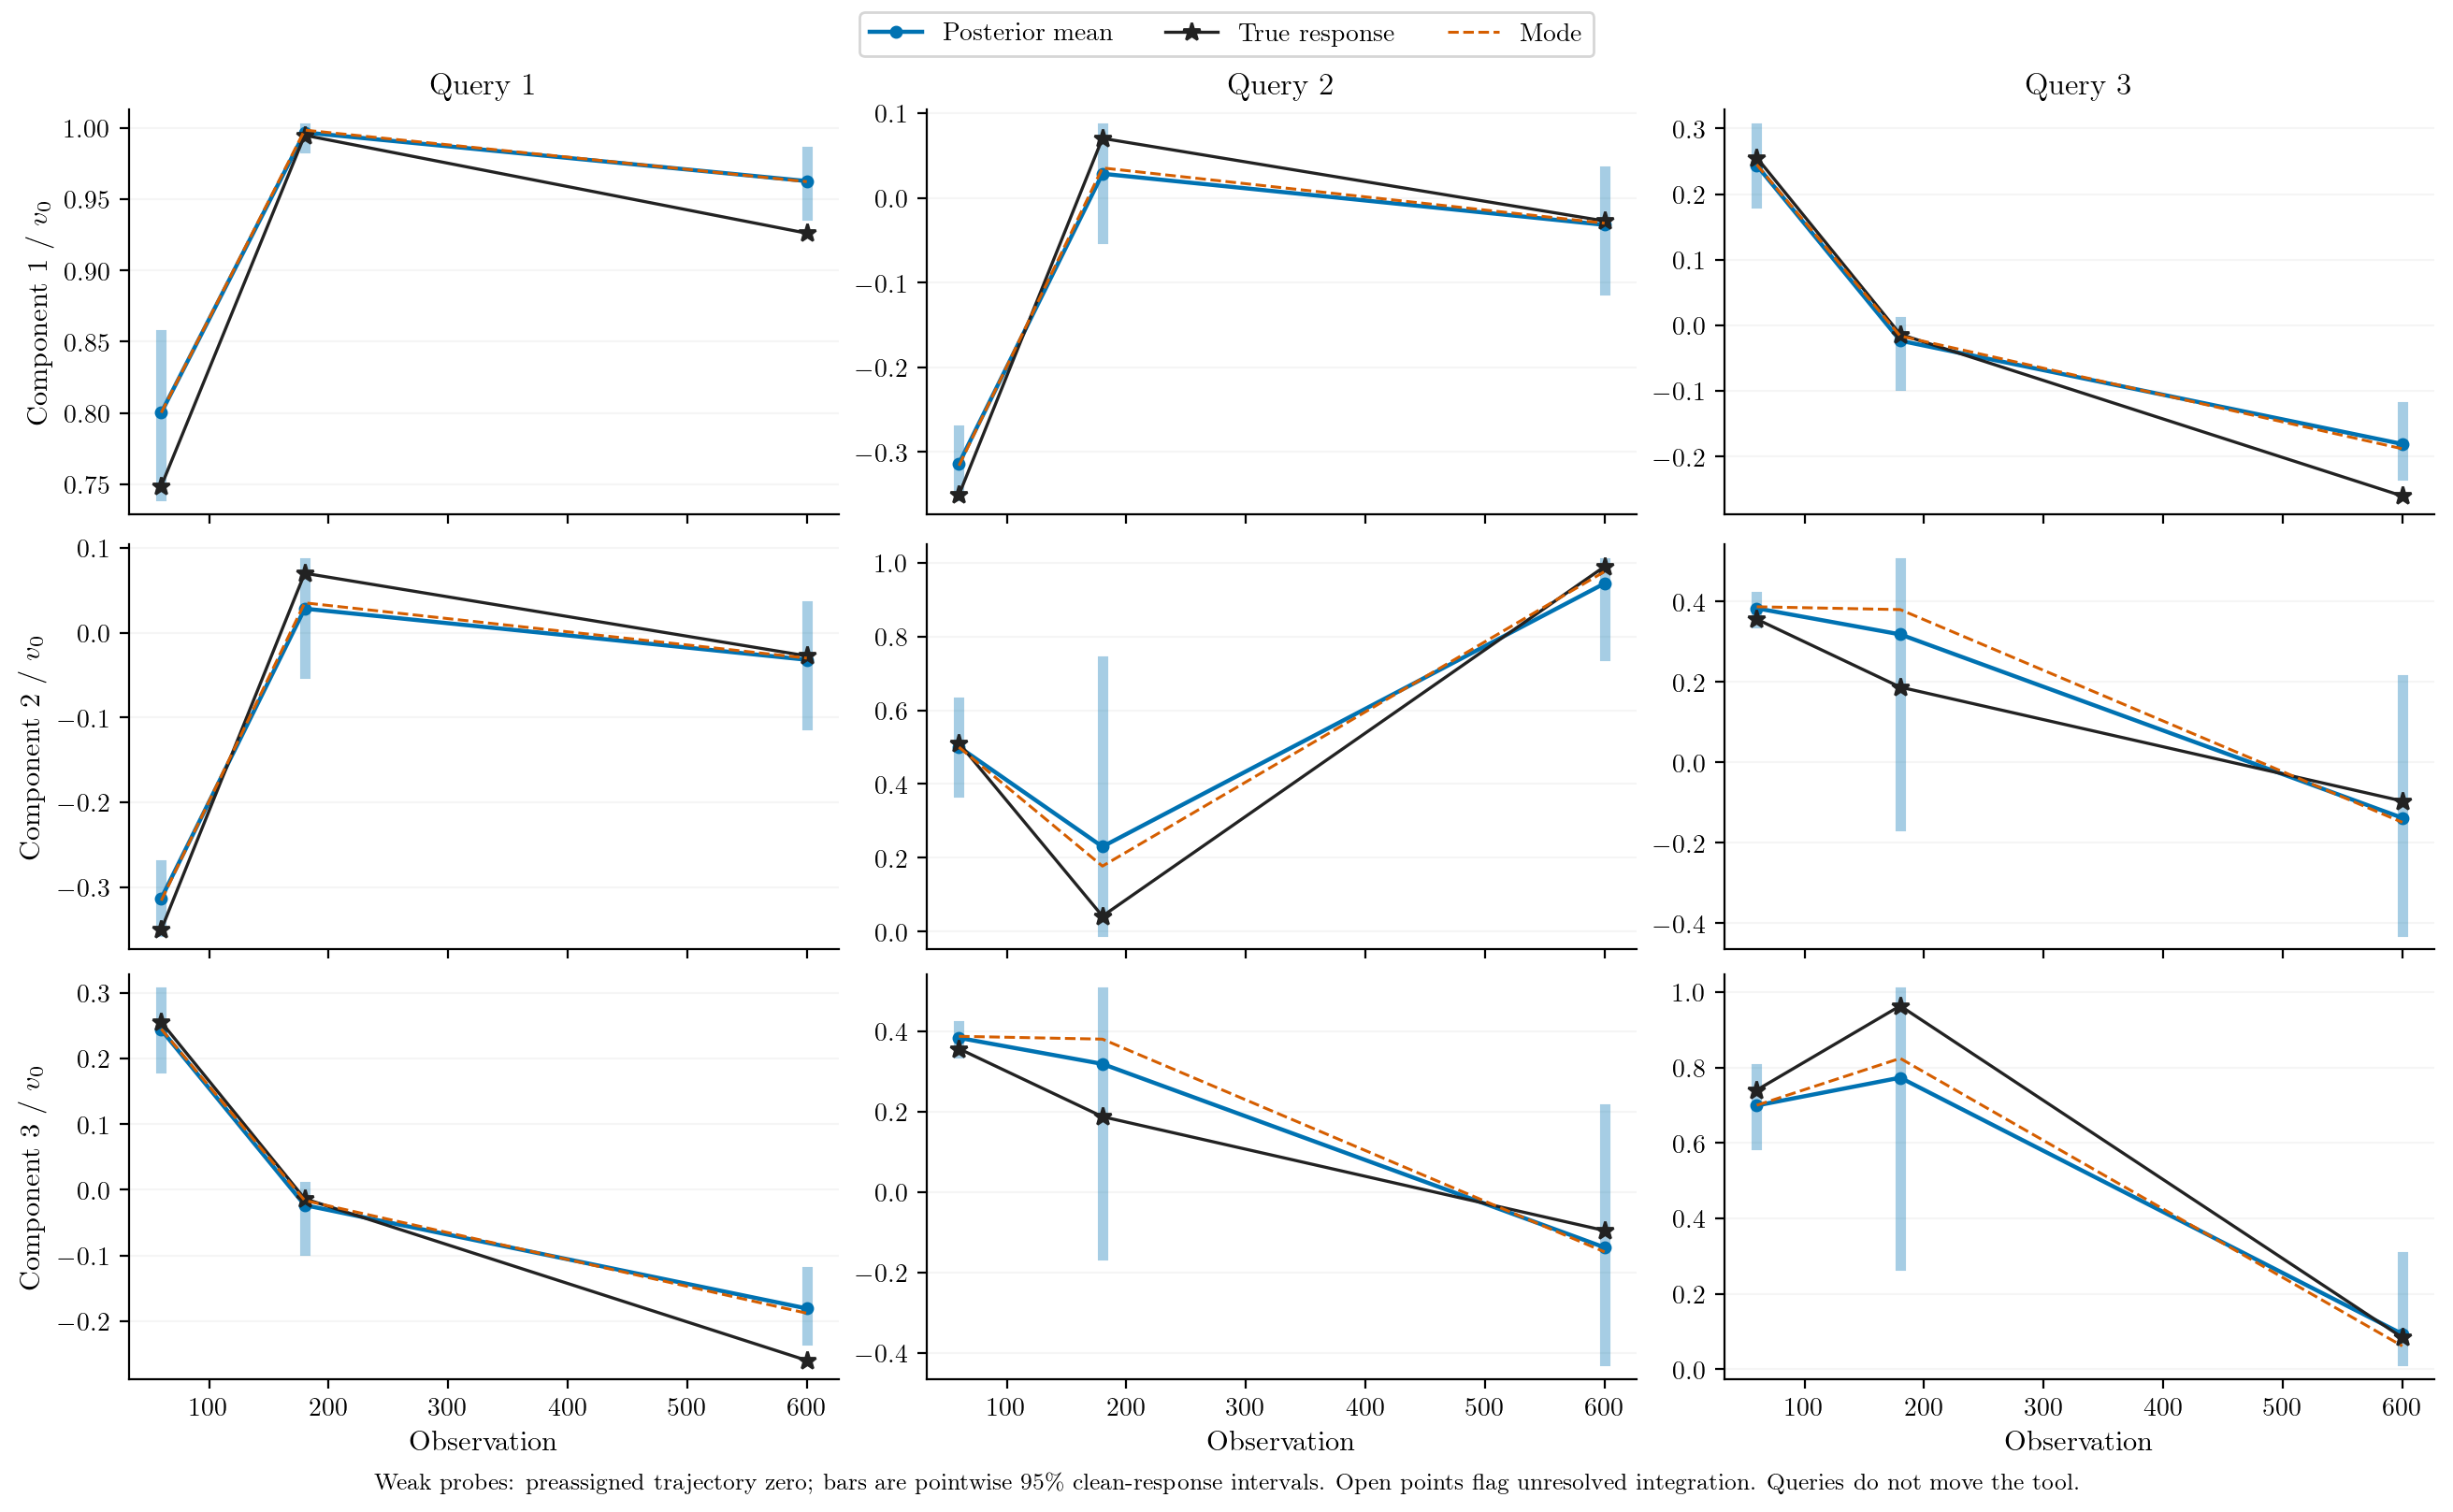

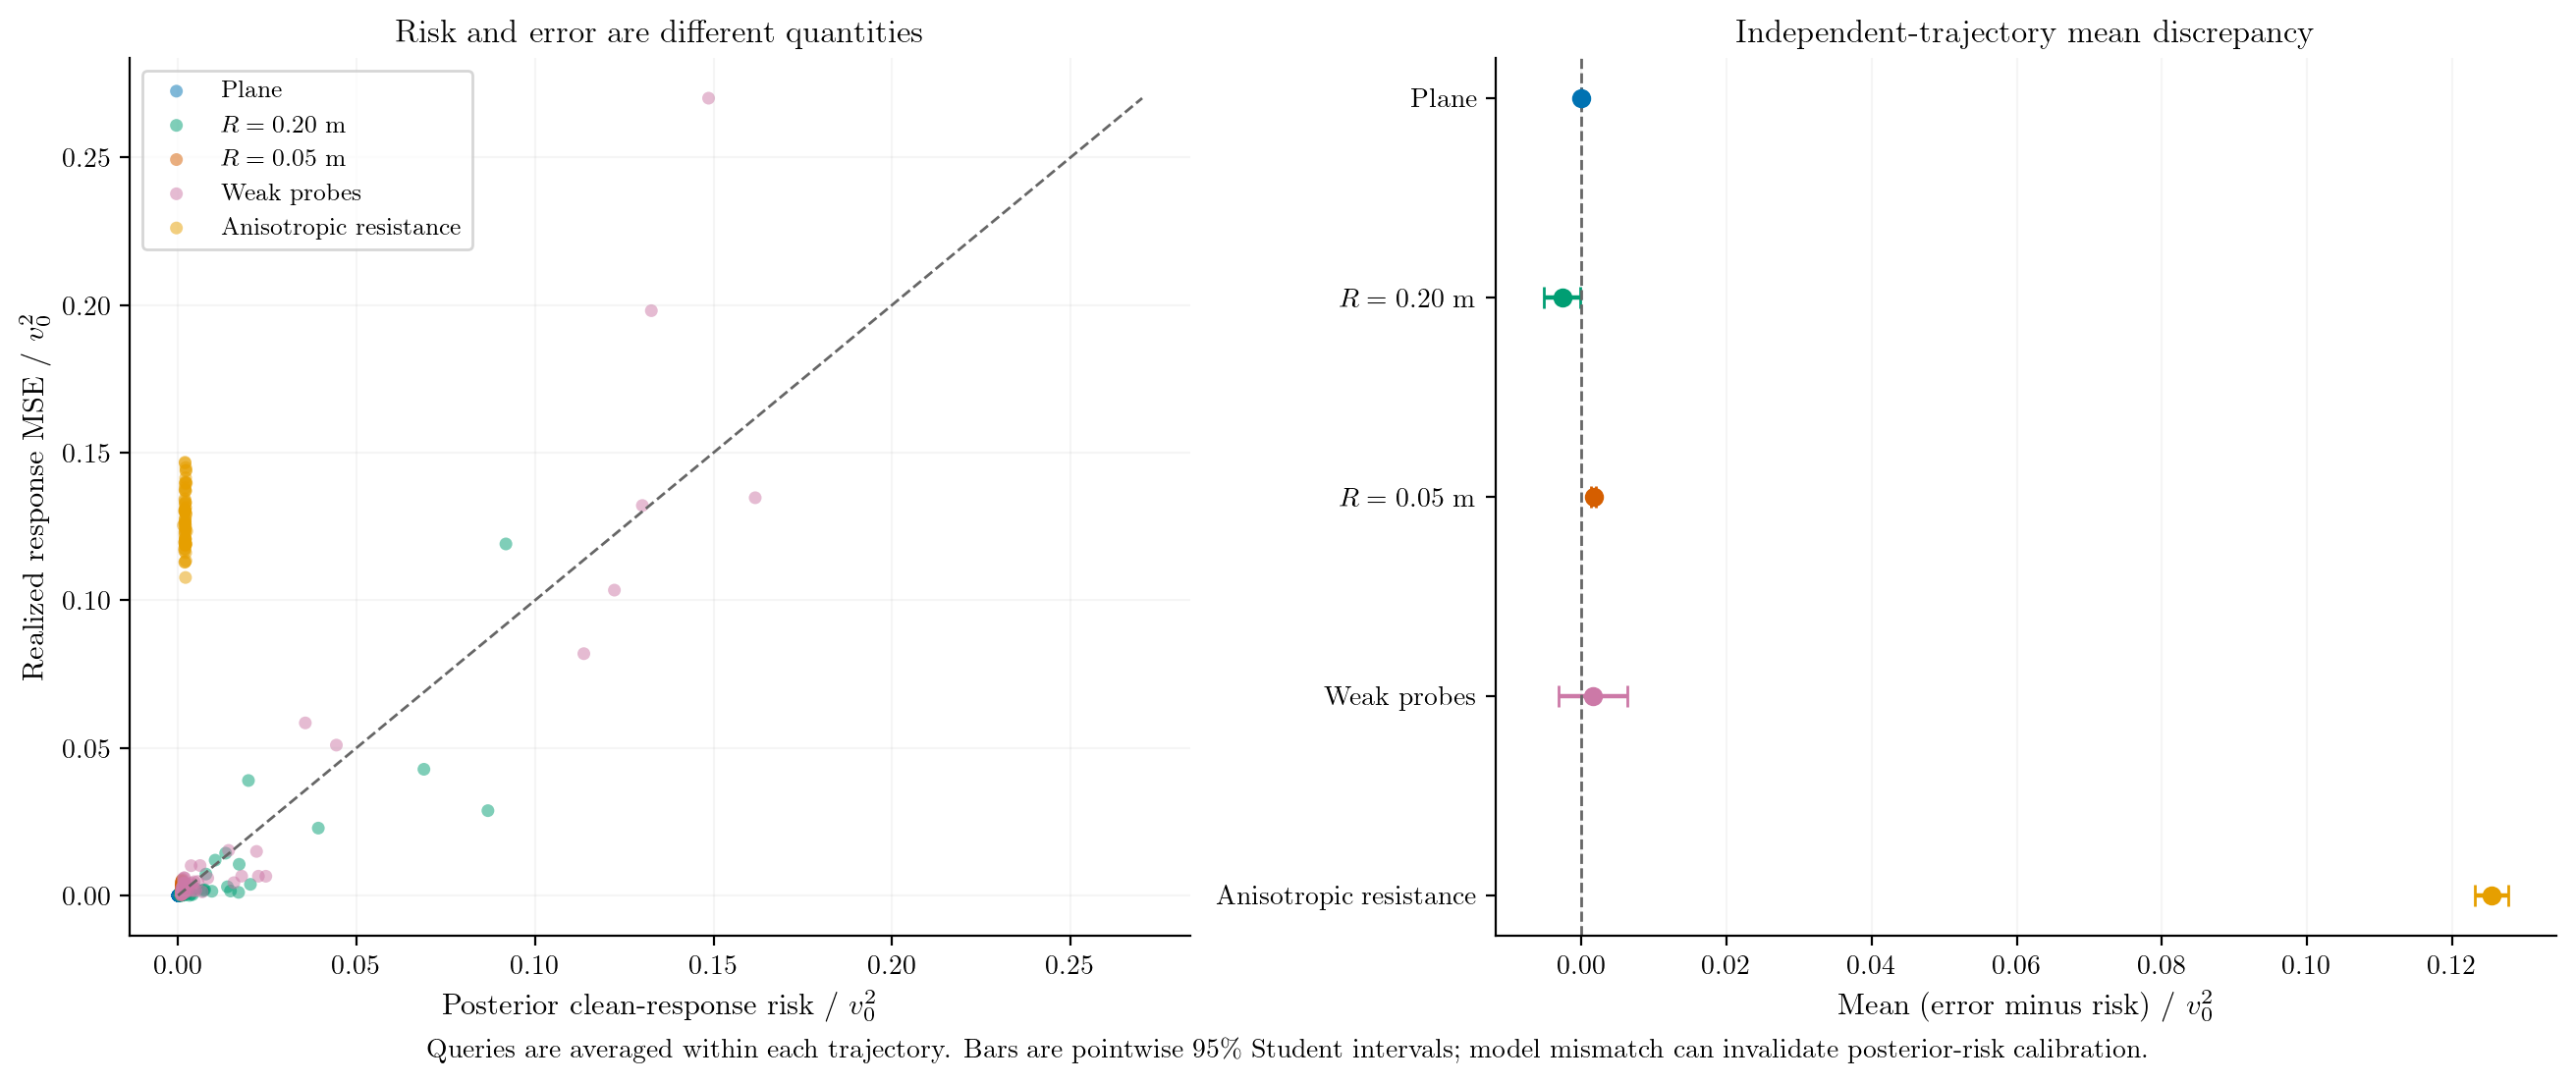

In [7]:
show(response_intervals(frames,path=OUT/'figures/response_intervals'))
show(risk_calibration(frames,path=OUT/'figures/risk_calibration'))

## Supplementary: geometry, excitation and the theorem

Radius alone does not measure tracking difficulty. The tables retain surface travel, normal rotation and retained force excitation. A small input-Gram eigenvalue does not by itself imply little information about the tangent plane. In normal tangent coordinates, the instantaneous information eigenvalues are
$$\lambda_{\min}=\frac{(n^\top v)^2}{s},\qquad
\lambda_{\max}=\frac{\|v\|^2}{s}.$$
Nearly normal forcing can be informative even when the observed noiseless velocity is close to zero.

The draft's modal bound is evaluated only under its real conditional model, fixed true noise and deterministic identity frame. It includes actual residual drift and may fail its sufficient condition. It is separate from every credible radius plotted here. The anisotropic-resistance stress is excluded from that theorem.

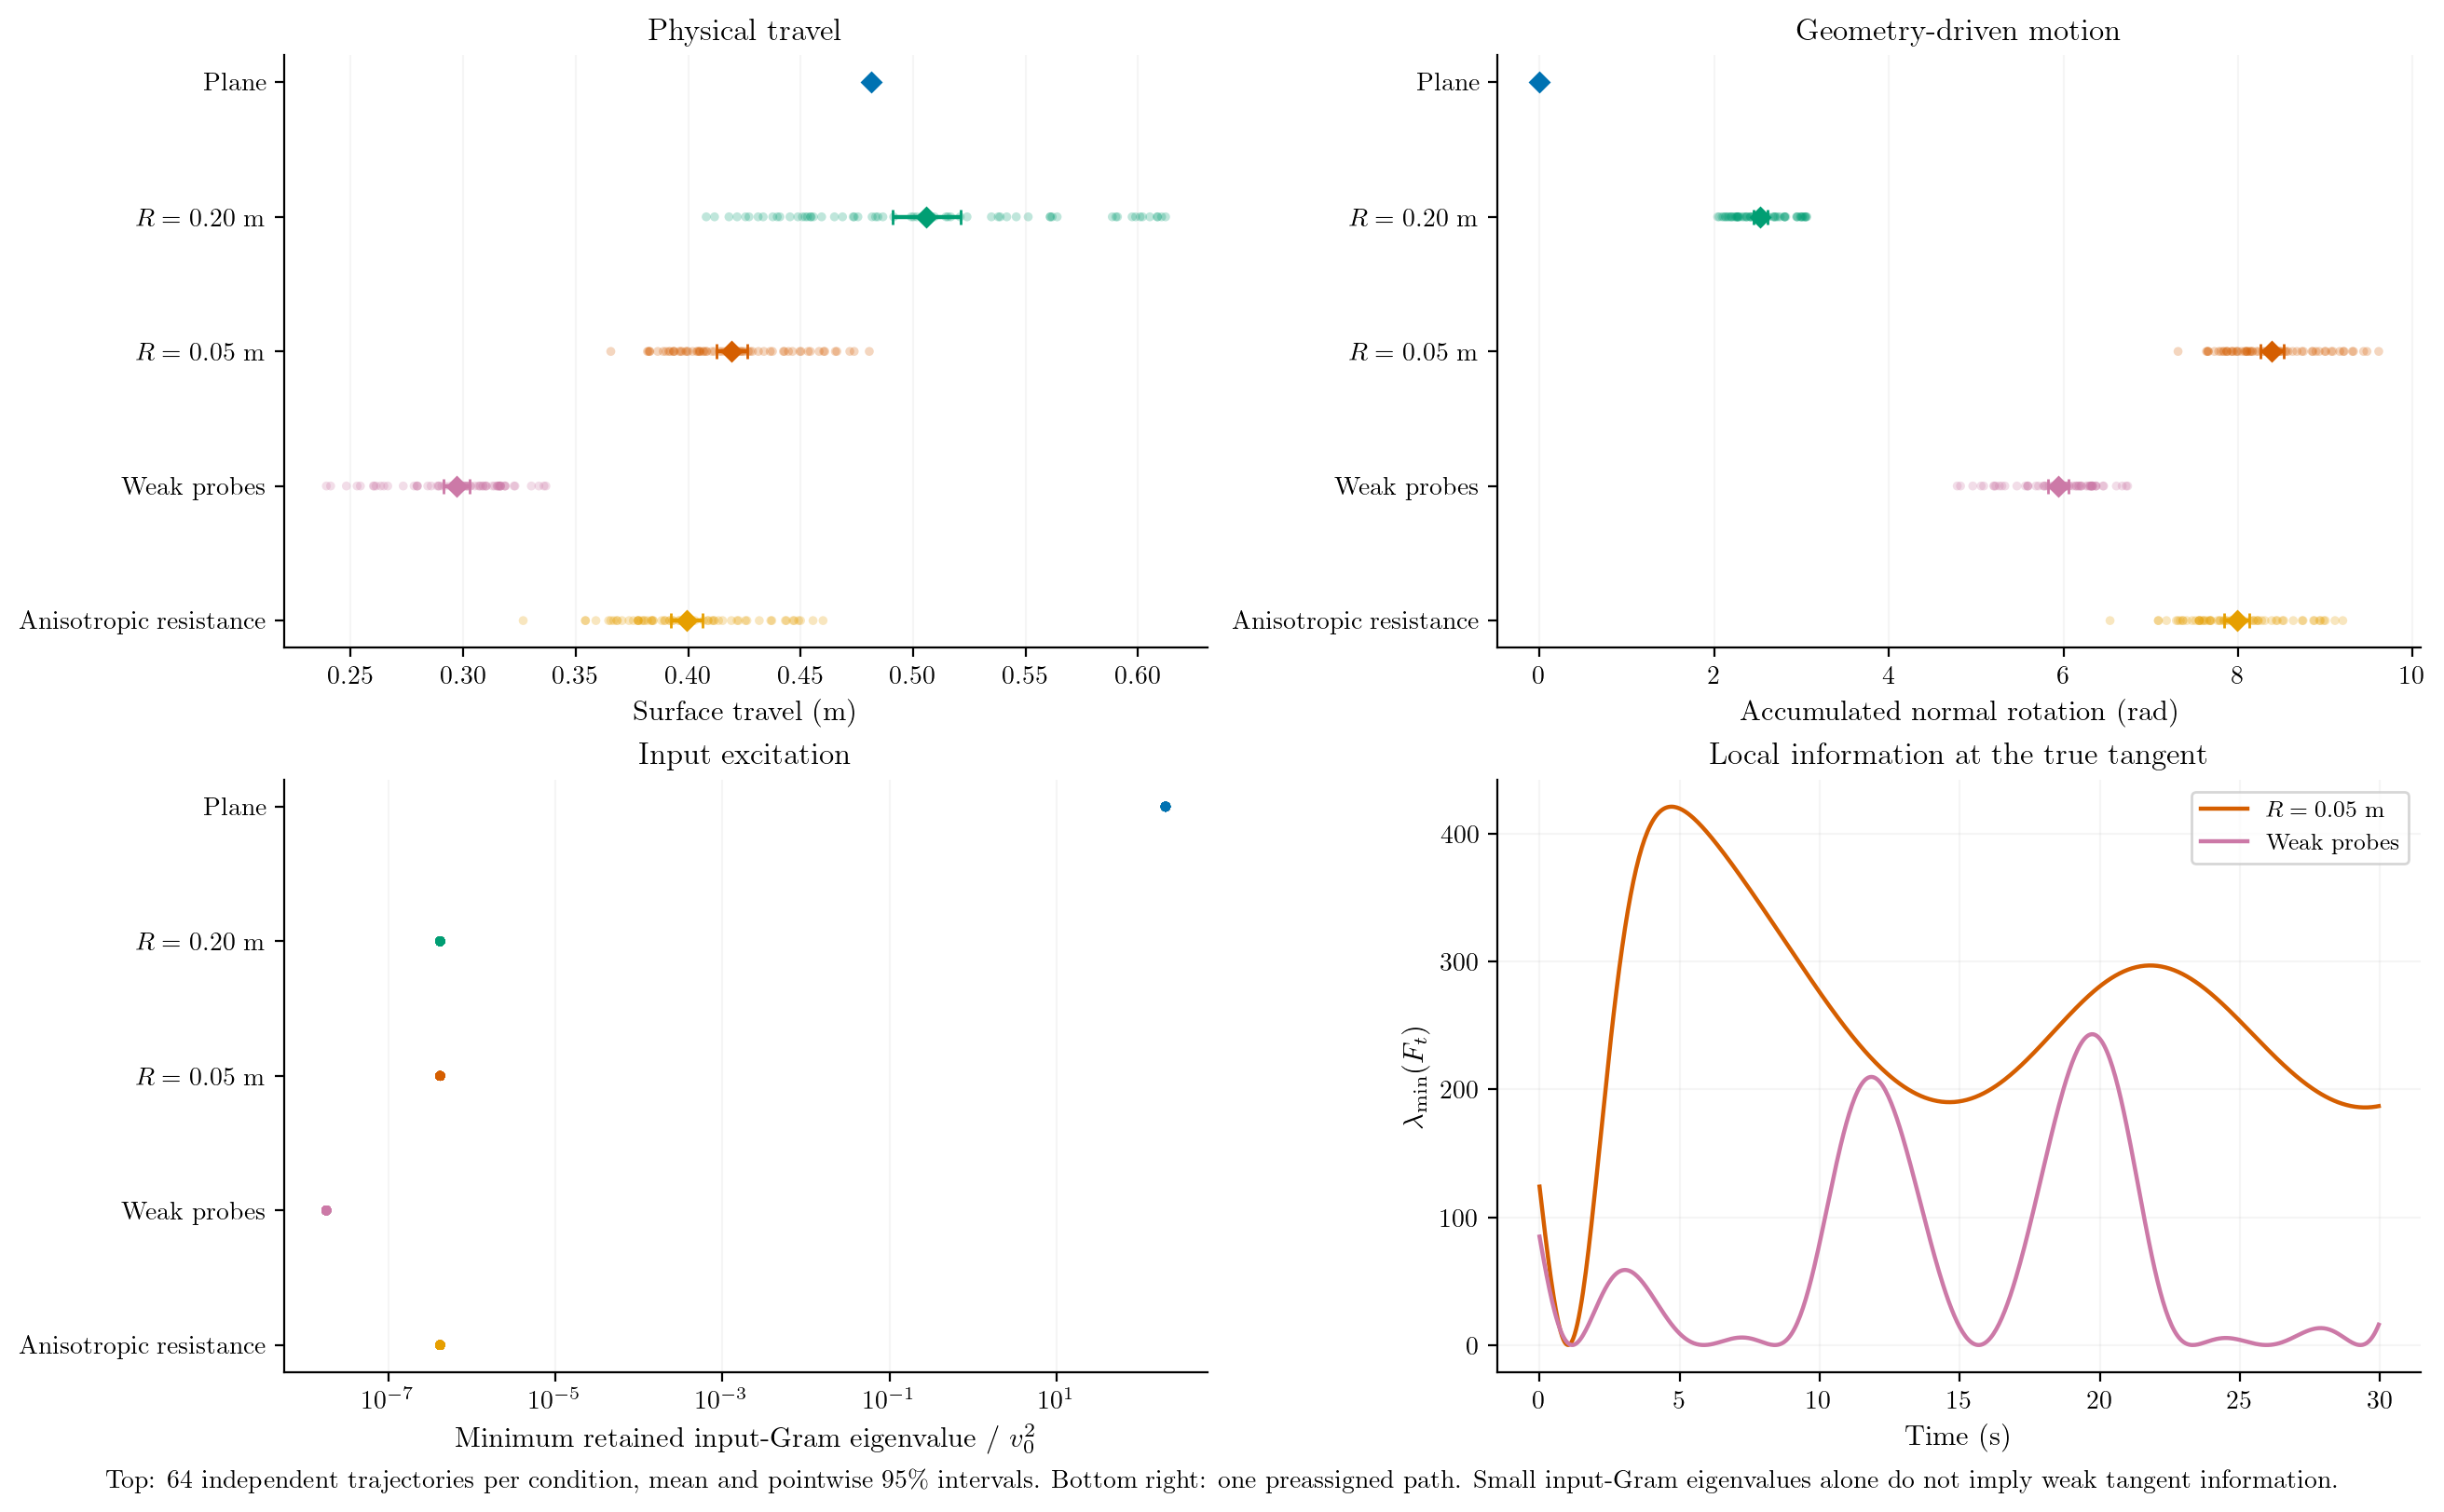

,applicable,valid,violated
condition,,,
anisotropic,0,0,0
plane,192,192,0
sphere_large,192,59,0
sphere_small,192,98,0
weak,192,40,0


In [8]:
show(mechanical_diagnostics(frames,path=OUT/'figures/mechanical_diagnostics'))
display(frames['bounds'].groupby('condition')[['applicable','valid','violated']].sum())

## Supplementary: resistance mismatch and cost

With true $D=d\,\mathrm{diag}(1,1.5,2)$, the KKT solve still defines a valid tangent velocity, but the response is generally not $P(F/d)$. The stress therefore scores actual KKT query velocities and retains the geometric projection target separately. Better memory does not repair this likelihood mismatch.

Corrections occur every observation; posterior integration and query decisions occur only at 60, 180 and 600. Runtime totals sum the three reports and the cumulative correction cost. A low correction time does not imply that all response intervals can be computed at the 20 Hz observation rate. These are cloud implementation measurements, not universal complexity claims.

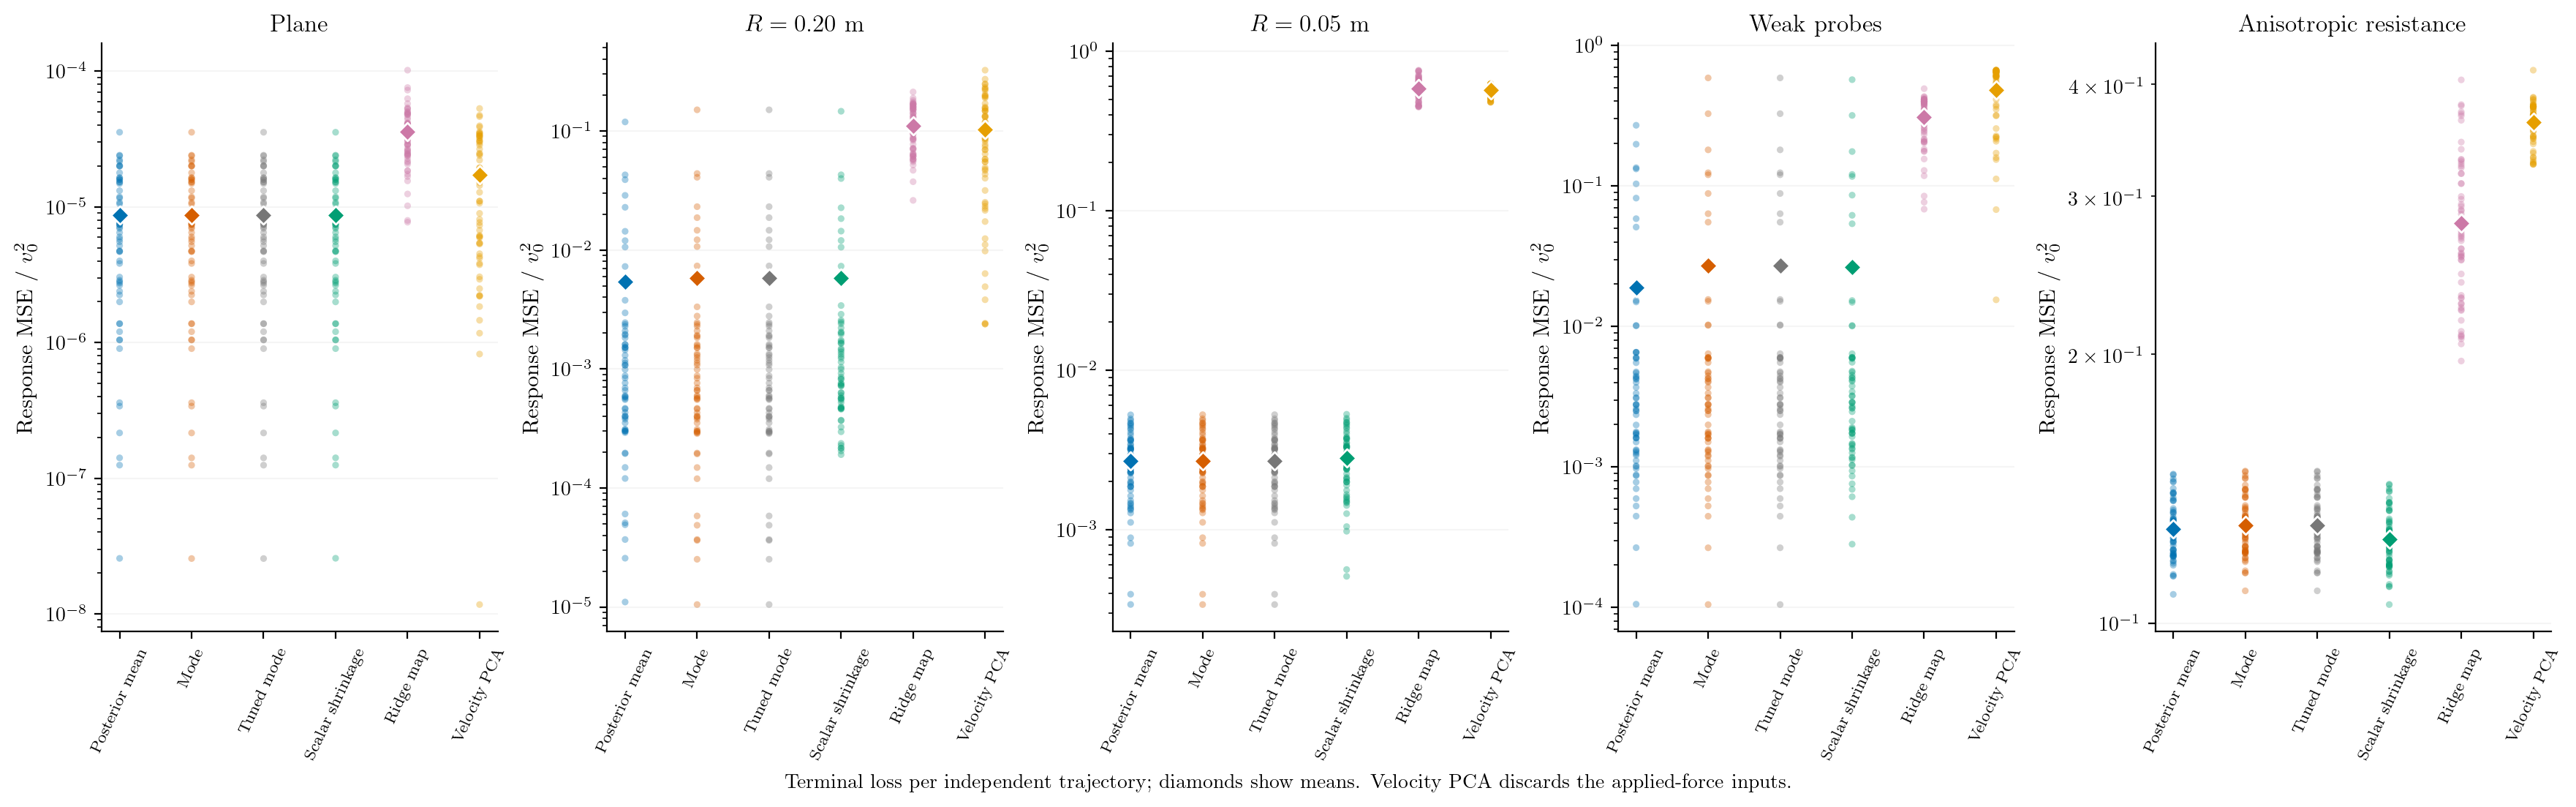

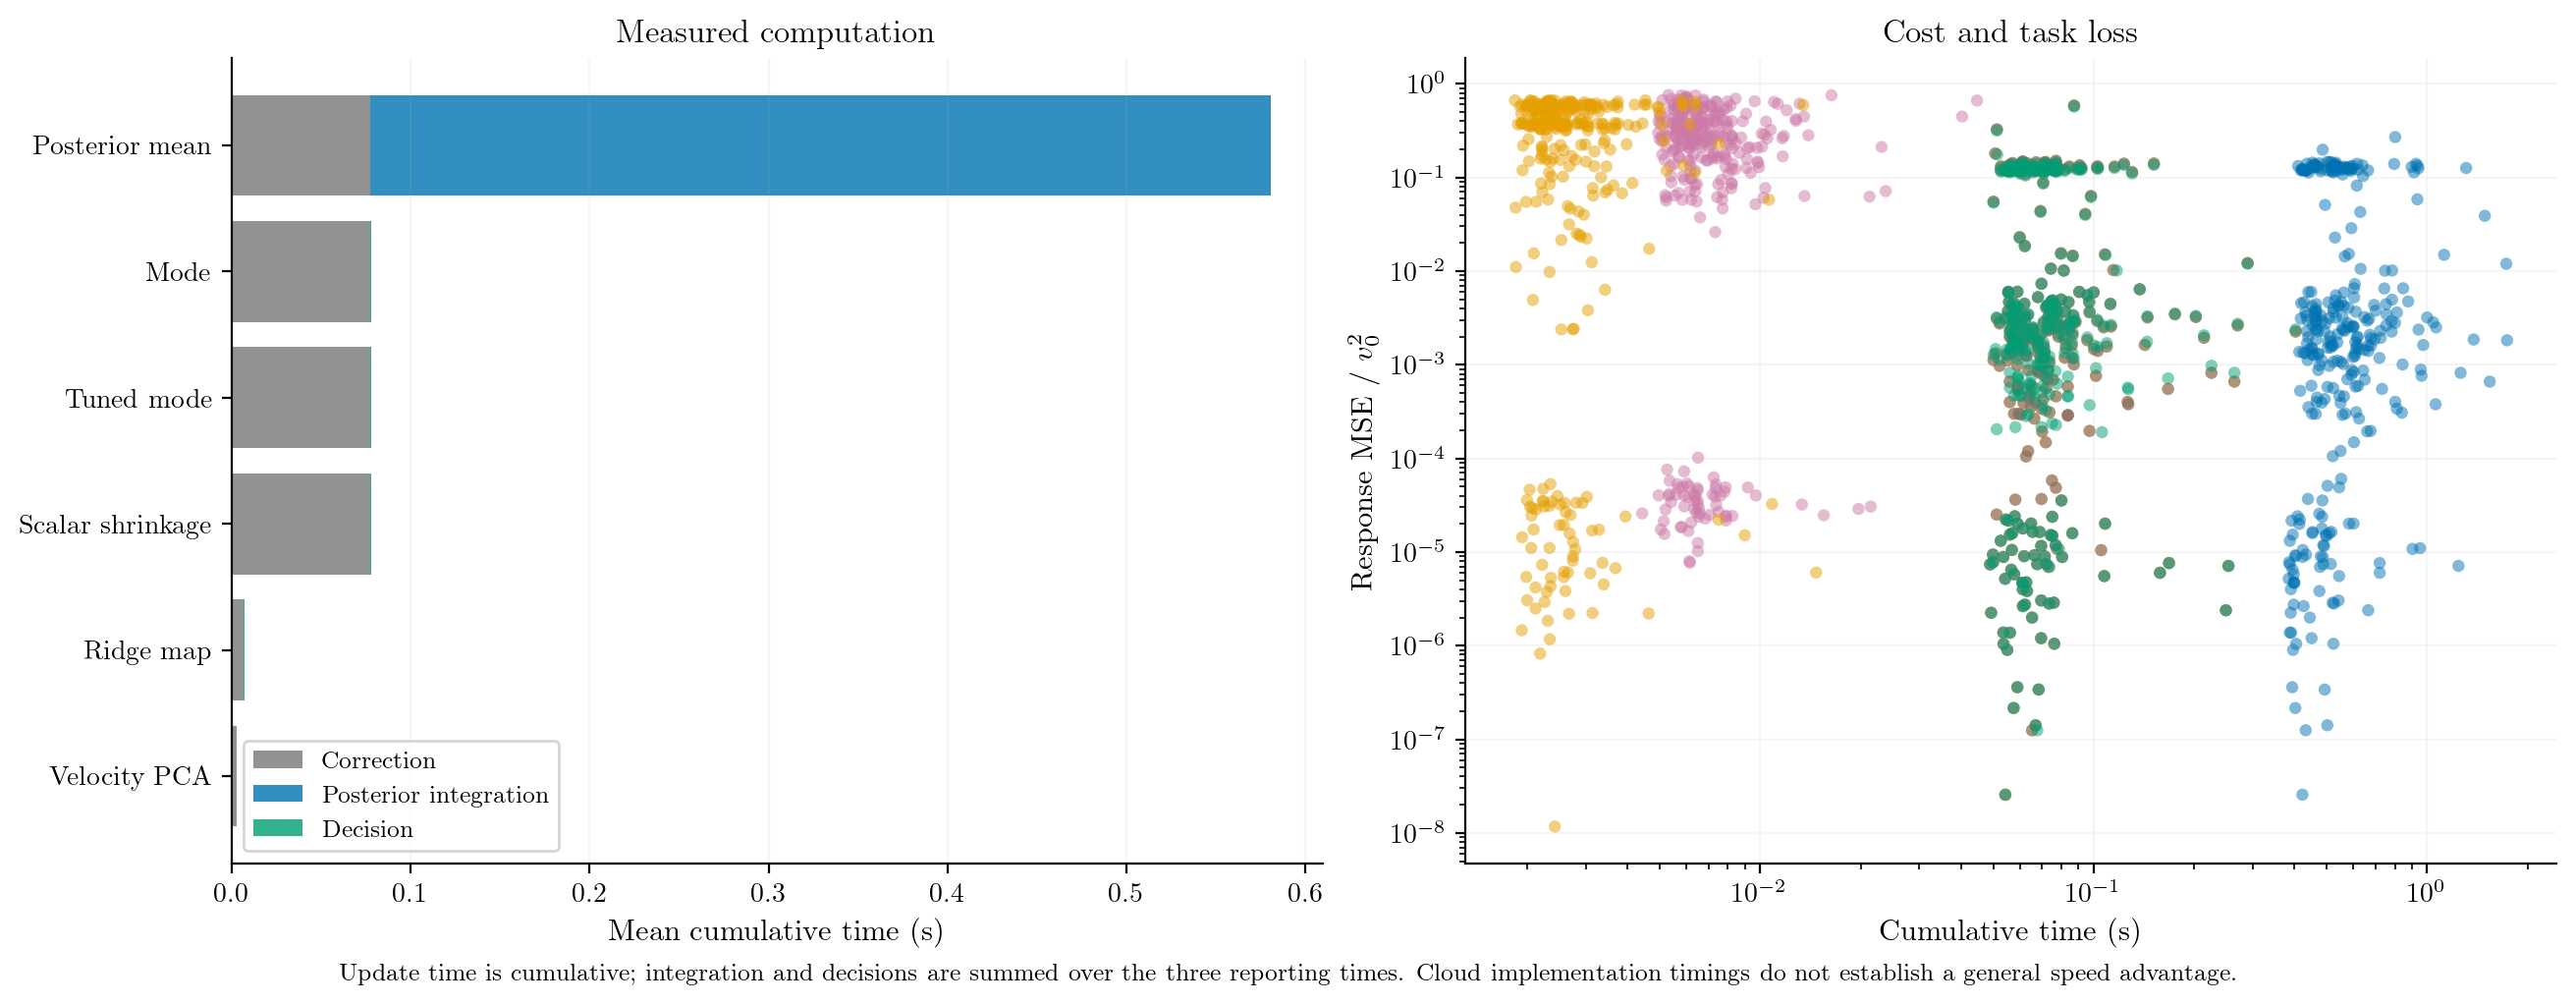

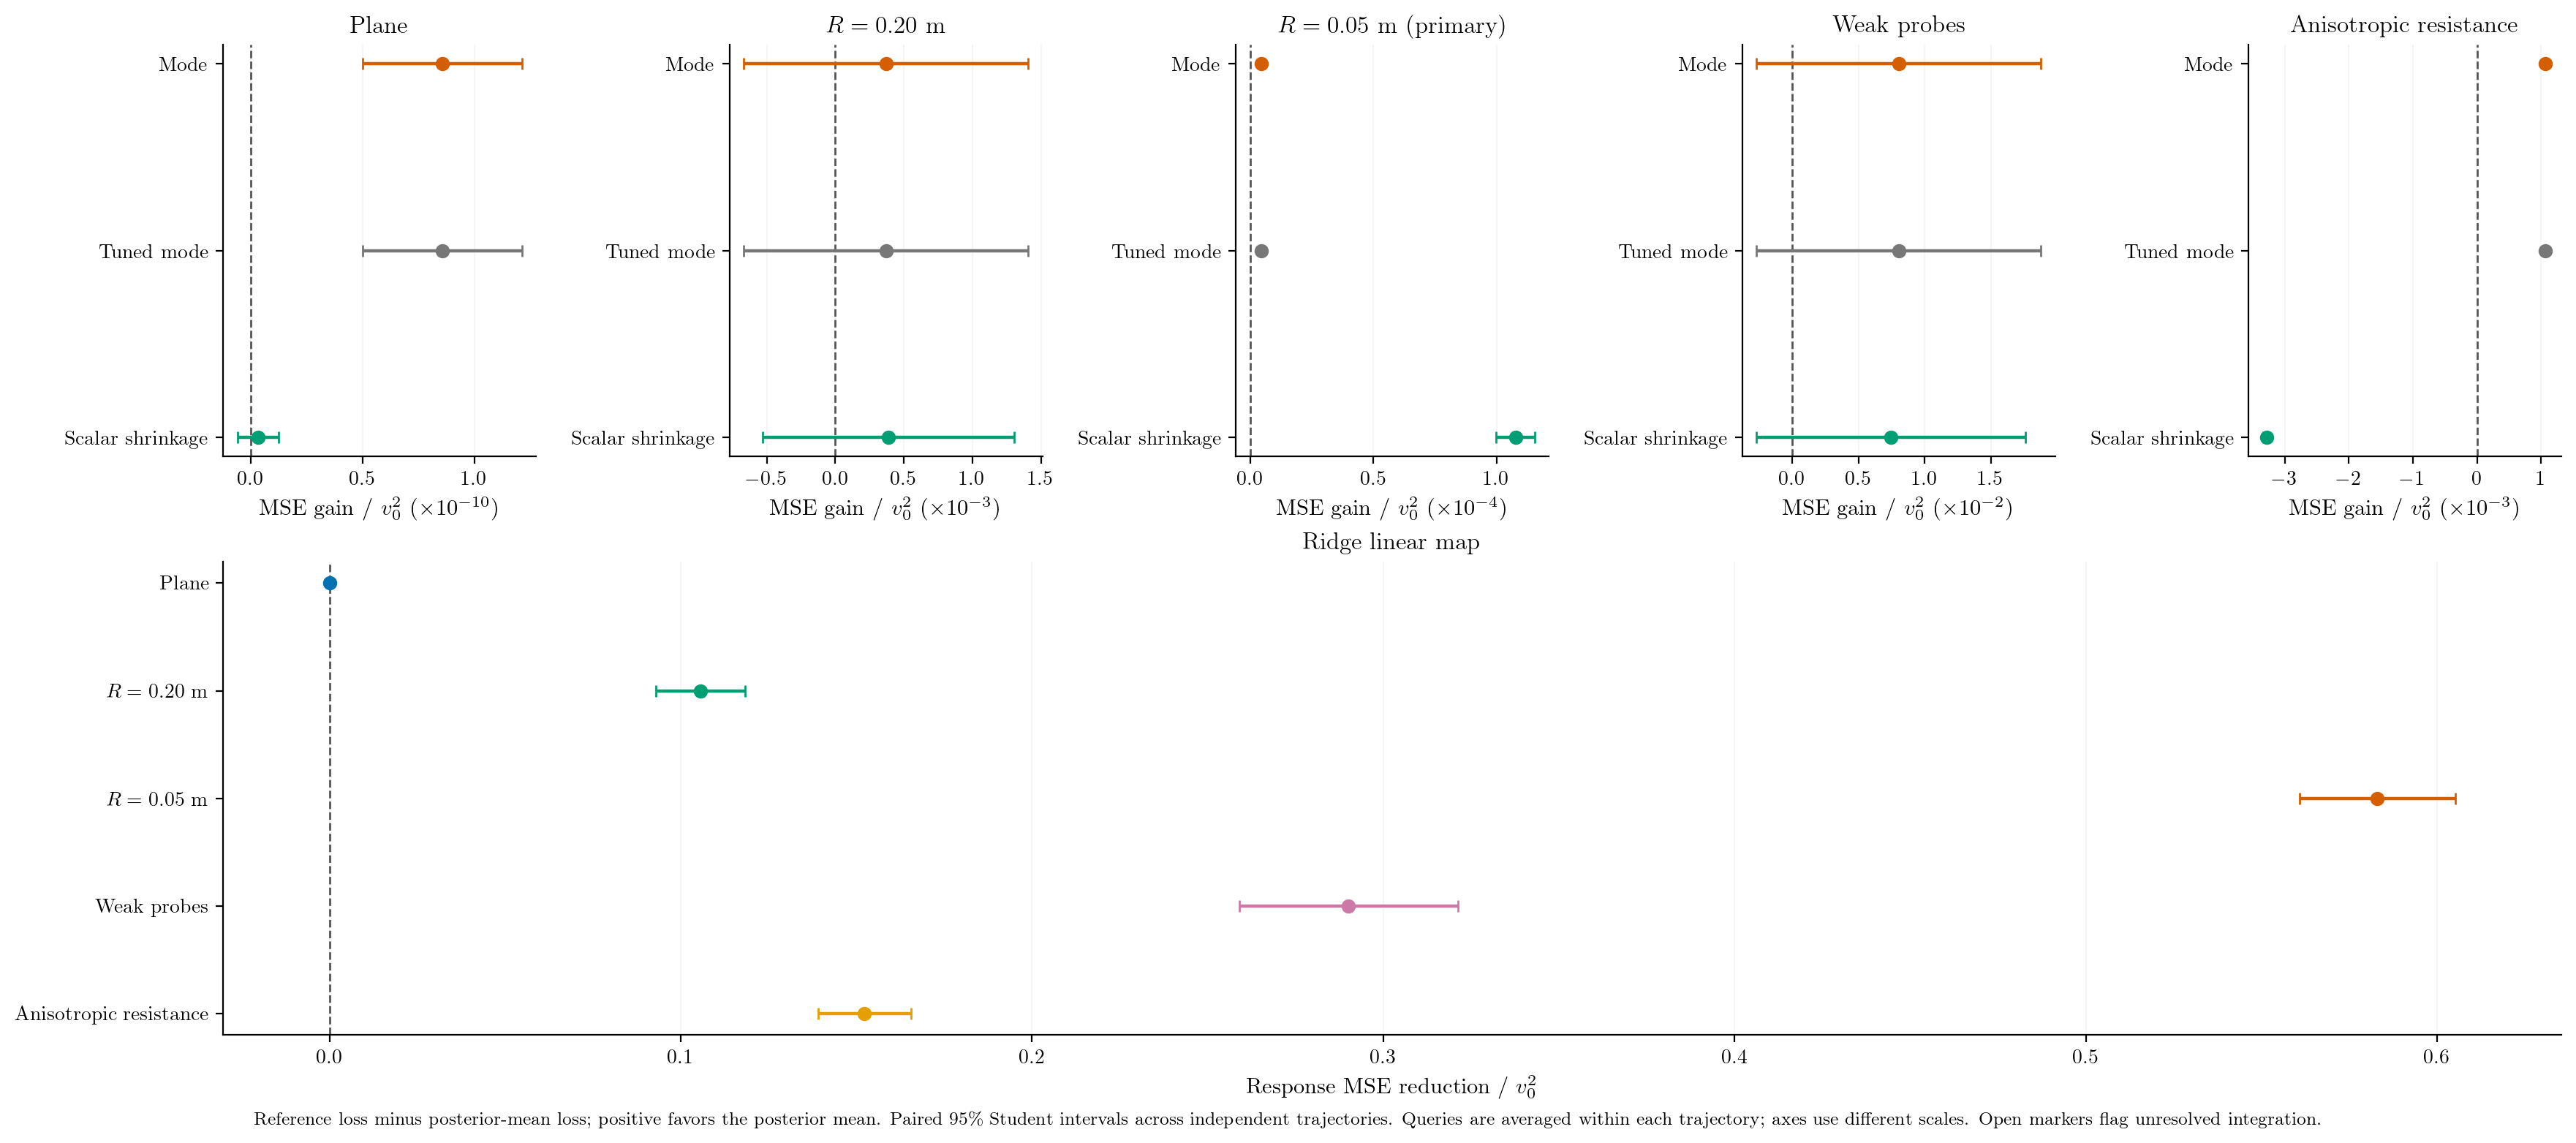

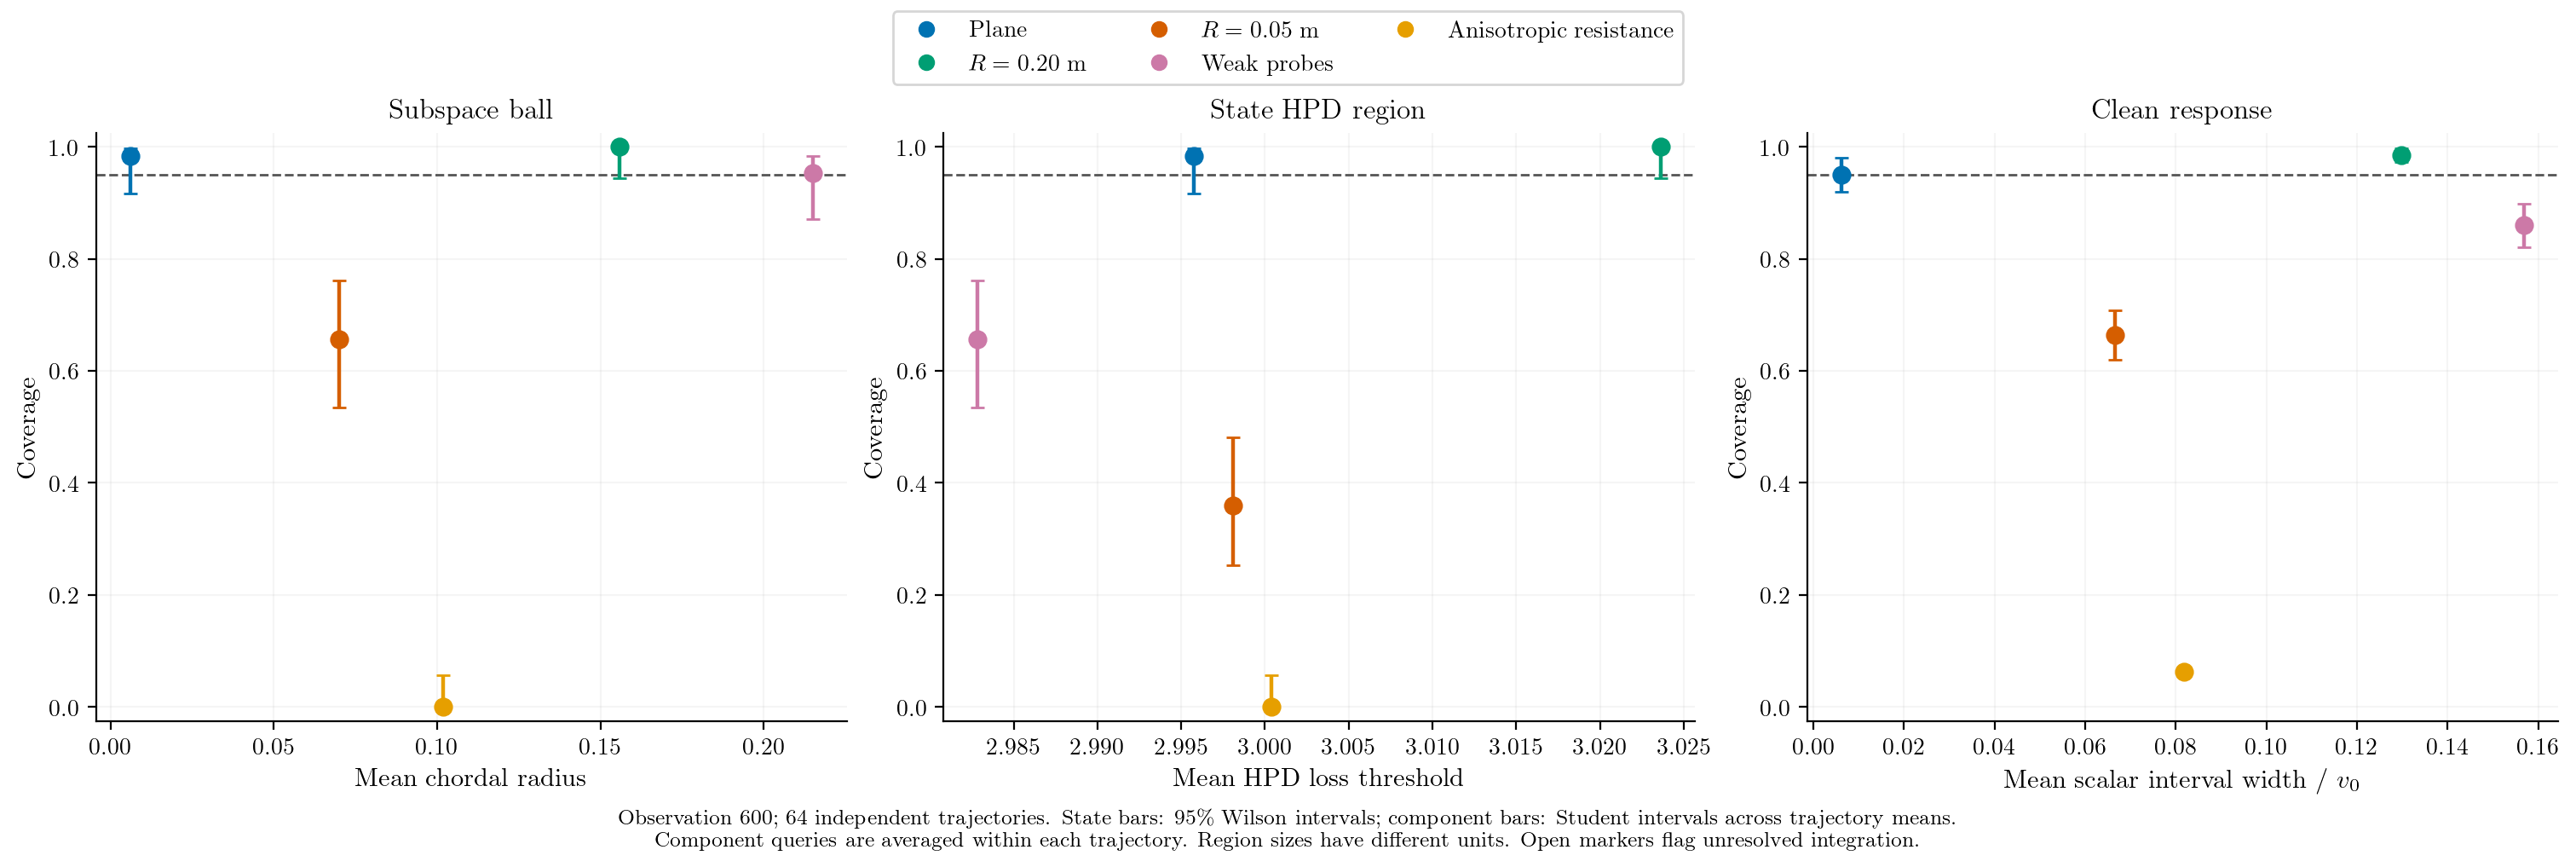

In [9]:
show(benchmark_losses(frames,path=OUT/'figures/benchmark_losses'))
show(runtime(frames,path=OUT/'figures/runtime'))
show(paired_losses(frames,path=OUT/'figures/paired_stress',include_stress=True))
show(coverage_width(frames,path=OUT/'figures/coverage_stress',include_stress=True))

## Supplementary: validation choices

These are validation curves, not extra test replications. One common curved policy is frozen before all curved tests. Scalar shrinkage minimizes the pooled validation quadratic continuously for each memory; the coarse scalar grid is retained only as a diagnostic. Structural endpoints and finite-grid memory/regularization boundaries are reported in the selected table. They do not establish global optimality.

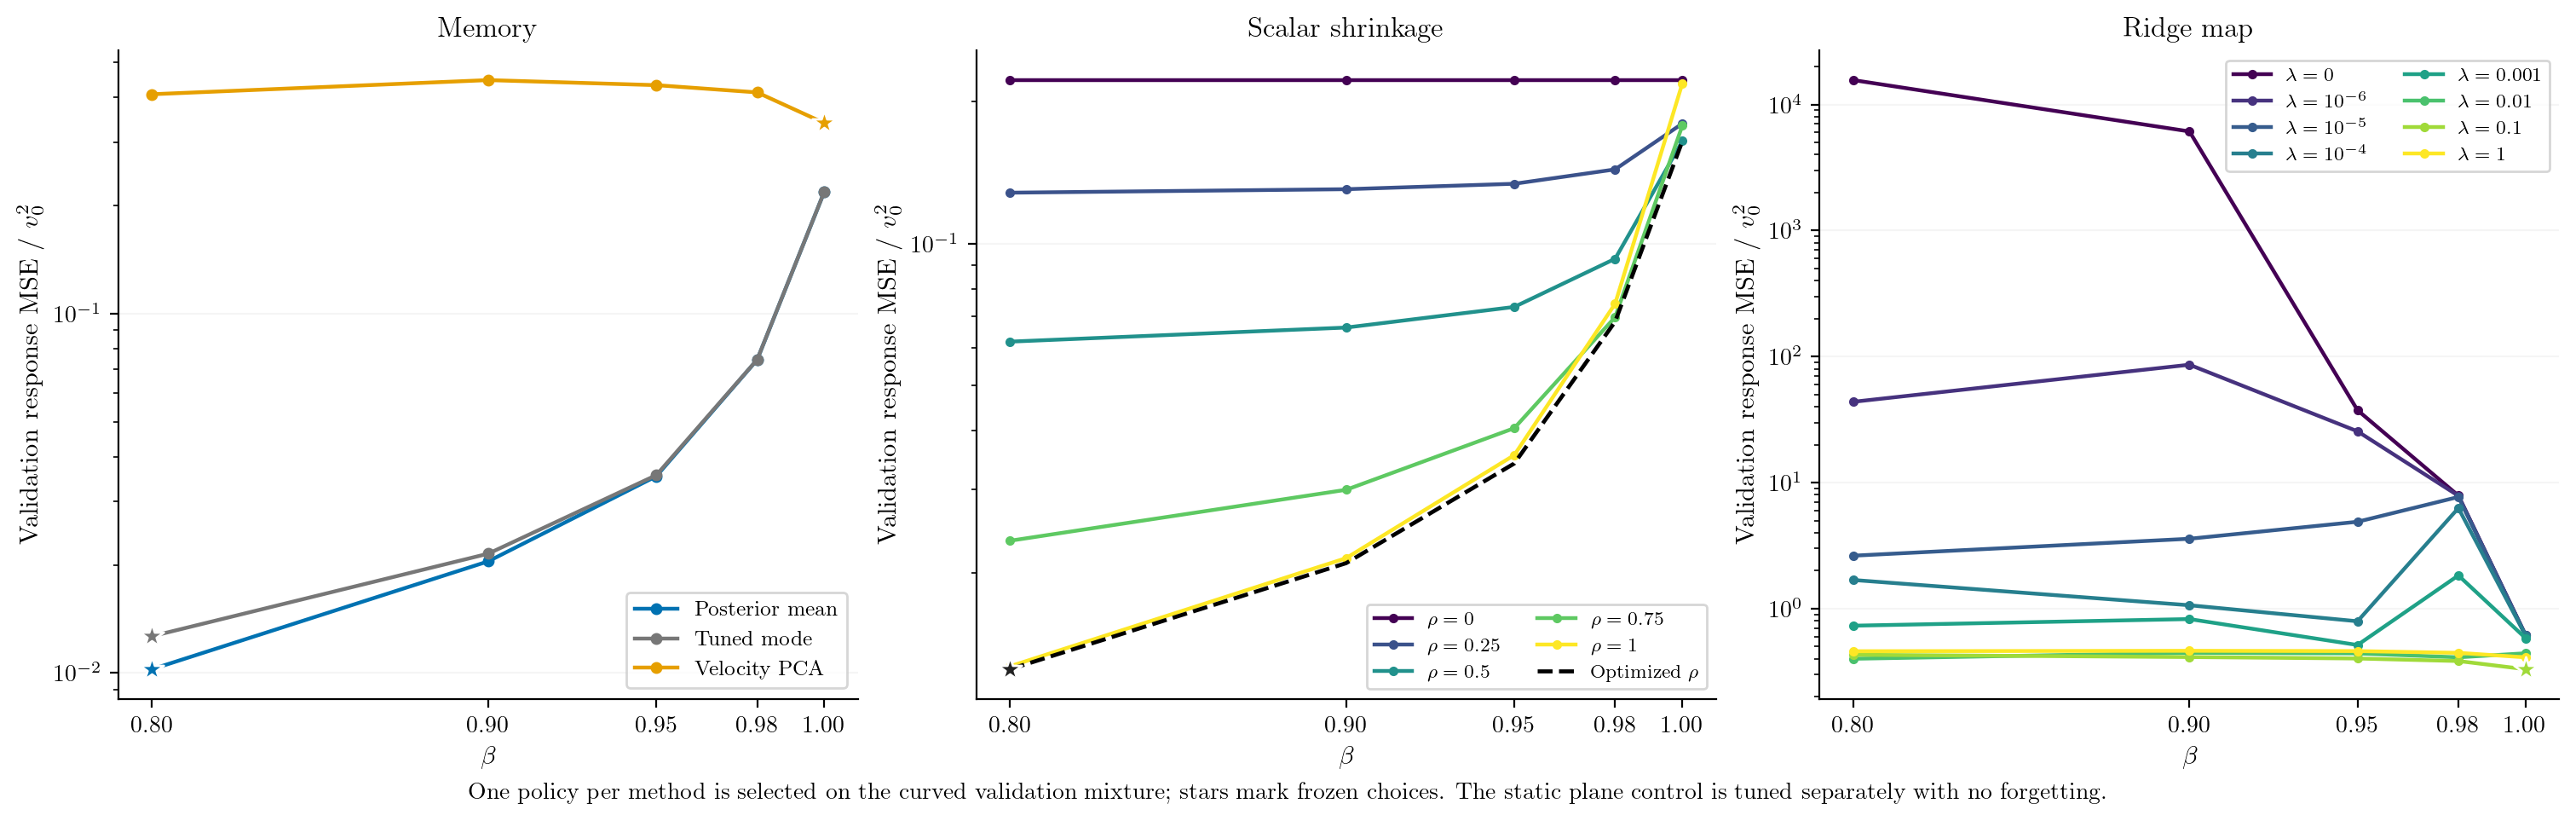

,scope,method,beta,validation_loss,se,independent_trials,evaluations,numerical_failures,selected,finite_grid_edge,boundary_note,rho,optimization,regularization
0,plane,Posterior mean,1.0,4.195645e-09,1.266012e-09,16,16,0,True,False,rho endpoints and beta=1/ridge=0 are structura...,NaN,NaN,NaN
1,plane,Tuned mode,1.0,4.195693e-09,1.266035e-09,16,16,0,True,False,rho endpoints and beta=1/ridge=0 are structura...,NaN,NaN,NaN
2,plane,Velocity PCA,1.0,6.166311e-09,1.379519e-09,16,16,0,True,False,rho endpoints and beta=1/ridge=0 are structura...,NaN,NaN,NaN
8,plane,Scalar shrinkage,1.0,4.195643e-09,1.266006e-09,16,16,0,True,False,Continuous pooled rho optimum; rho0/1 are stru...,0.999976,Analytic common rho from pooled independent va...,NaN
9,plane,Ridge map,1.0,1.527756e-08,2.159789e-09,16,16,0,True,False,rho endpoints and beta=1/ridge=0 are structura...,NaN,NaN,0.0
17,curved,Posterior mean,0.8,4.098291e-06,1.597009e-06,16,48,0,True,True,rho endpoints and beta=1/ridge=0 are structura...,NaN,NaN,NaN
22,curved,Tuned mode,0.8,5.063874e-06,2.811341e-06,16,48,0,True,True,rho endpoints and beta=1/ridge=0 are structura...,NaN,NaN,NaN
31,curved,Velocity PCA,1.0,1.357014e-04,9.860357e-06,16,48,0,True,False,rho endpoints and beta=1/ridge=0 are structura...,NaN,NaN,NaN
57,curved,Scalar shrinkage,0.8,4.991753e-06,2.731261e-06,16,48,0,True,True,Continuous pooled rho optimum; rho0/1 are stru...,0.971516,Analytic common rho from pooled independent va...,NaN
100,curved,Ridge map,1.0,1.322178e-04,8.729121e-06,16,48,0,True,False,rho endpoints and beta=1/ridge=0 are structura...,NaN,NaN,0.1


In [10]:
show(validation_curves(frames,path=OUT/'figures/validation_curves'))
display(frames['tuning'][frames['tuning'].selected.astype(bool)])

## Interpretation for robotics

This pilot tests a force/velocity response model for a maintained, quasi-static bilateral guide. It is not a contact detector, a frictional polishing simulation, or a validation on a real robot. The Grassmann state represents an unoriented tangent plane; it does not encode the sign of a unilateral normal or whether contact can sustain tension.

The posterior mean $E[P]$ is generally full rank and does not itself define one contact tangent plane. Its output is an expected velocity prediction, not a guarantee of a physically admissible velocity command at the actual surface. The experiment is open loop with prescribed forces; no closed-loop controller, robot-arm dynamics or safe-contact policy is evaluated.

Positions would normally be available on many robots. They are deliberately not a measurement channel here, so practical claims require a later comparison with a causal local-plane estimate from the same noisy encoder stream. Unknown or anisotropic resistance also requires a different observation model; it should not be absorbed into measurement noise or described as repaired by discounting.

No process-noise machinery or paper-scope change is introduced. The code and evidence remain separate so the replacement decision can be made after this bounded test. Robotics context: Lin, Howard and Vijayakumar, *Learning Null Space Projections*, ICRA 2015, DOI 10.1109/ICRA.2015.7139551. The mechanical realization here is the proposed pilot, not a reproduction of that paper.